<a href="https://colab.research.google.com/github/narayankarrahe/APPLIANCES-ENERGY-PREDICTION-USING-MACHINE-LEARNING-DEEP-LEARNING/blob/main/AEP_vif.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
1. #Initial Data Cleaning and Transformation - Data Preprocessing
#Import and load original file
import pandas as pd
import numpy as np

df = pd.read_excel("/content/Appliances Energy Prediciton.xlsx")

print("Original Shape:", df.shape)
df.head()

Original Shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [ ]:
2. ##basic information
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)


Columns:
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']

Data Types:
date           datetime64[ns]
Appliances              int64
lights                  int64
T1                    float64
RH_1                  float64
T2                    float64
RH_2                  float64
T3                    float64
RH_3                  float64
T4                    float64
RH_4                  float64
T5                    float64
RH_5                  float64
T6                    float64
RH_6                  float64
T7                    float64
RH_7                  float64
T8                    float64
RH_8                  float64
T9                    float64
RH_9                  float64
T_out                 float64
Press_mm_hg           float64
RH_out                float64
Windspeed  

In [ ]:
3.#Check missing values
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

Missing Values:
date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

Total Missing Values: 0


In [ ]:
4. #Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
5. #Remove unwanted columns
df.drop(['rv1', 'rv2'], axis=1, inplace=True)

In [ ]:
6. #Check constant columns
for column in df.columns:
    if df[column].nunique() == 1:
        print("Constant column:", column)

In [ ]:
7. #Create useful new columns
df['Month'] = df['date'].dt.month
df['Hour'] = df['date'].dt.hour

In [ ]:
8. #remove original date
df.drop('date', axis=1 , inplace=True)

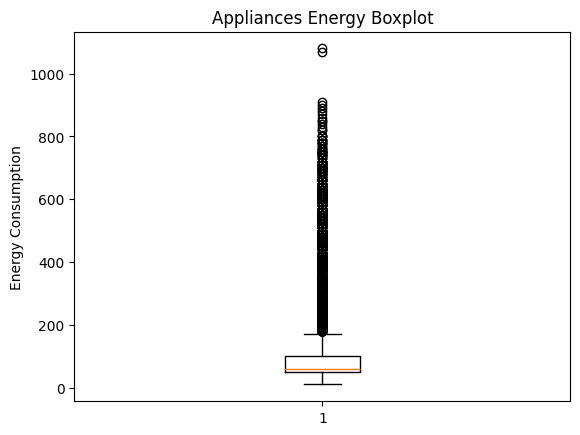

In [ ]:
9. #Check outliers
import matplotlib.pyplot as plt

plt.boxplot(df['Appliances'])

plt.title("Appliances Energy Boxplot")
plt.ylabel("Energy Consumption")

plt.show()

In [ ]:
10. #Final preprocessing check
print("Final Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Final Shape: (19735, 28)

Missing Values:
0

Duplicate Rows:
0


In [ ]:
11. #View Final data
df.head()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,Month,Hour
0,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,1,17
1,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,1,17
2,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,1,17
3,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,1,17
4,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,1,17


In [ ]:
12.#Save updated excel
output_file = "Updated_Appliances_Energy_Prediction.xlsx"

df.to_excel(output_file, index=False)

print("Updated Appliances Energy Prediction file created successfully!")

Updated Appliances Energy Prediction file created successfully!


In [ ]:
13. #Download updated Excel
from google.colab import files

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
14. #EDA
#Load the updated dataset
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("/content/Updated_Appliances_Energy_Prediction.xlsx")

print(df.shape)
df.head()

(19735, 28)


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,Month,Hour
0,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,1,17
1,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,1,17
2,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,1,17
3,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,1,17
4,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,1,17


In [ ]:
15. #Descriptive statistics
df.describe()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,Month,Hour
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,3.101647,11.502002
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,1.339200,6.921953
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,1.000000,0.000000
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,2.000000,6.000000
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,3.000000,12.000000
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,4.000000,17.000000
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,5.000000,23.000000


In [ ]:
16. #Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 28 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Appliances   19735 non-null  int64  
 1   lights       19735 non-null  int64  
 2   T1           19735 non-null  float64
 3   RH_1         19735 non-null  float64
 4   T2           19735 non-null  float64
 5   RH_2         19735 non-null  float64
 6   T3           19735 non-null  float64
 7   RH_3         19735 non-null  float64
 8   T4           19735 non-null  float64
 9   RH_4         19735 non-null  float64
 10  T5           19735 non-null  float64
 11  RH_5         19735 non-null  float64
 12  T6           19735 non-null  float64
 13  RH_6         19735 non-null  float64
 14  T7           19735 non-null  float64
 15  RH_7         19735 non-null  float64
 16  T8           19735 non-null  float64
 17  RH_8         19735 non-null  float64
 18  T9           19735 non-null  float64
 19  RH_9

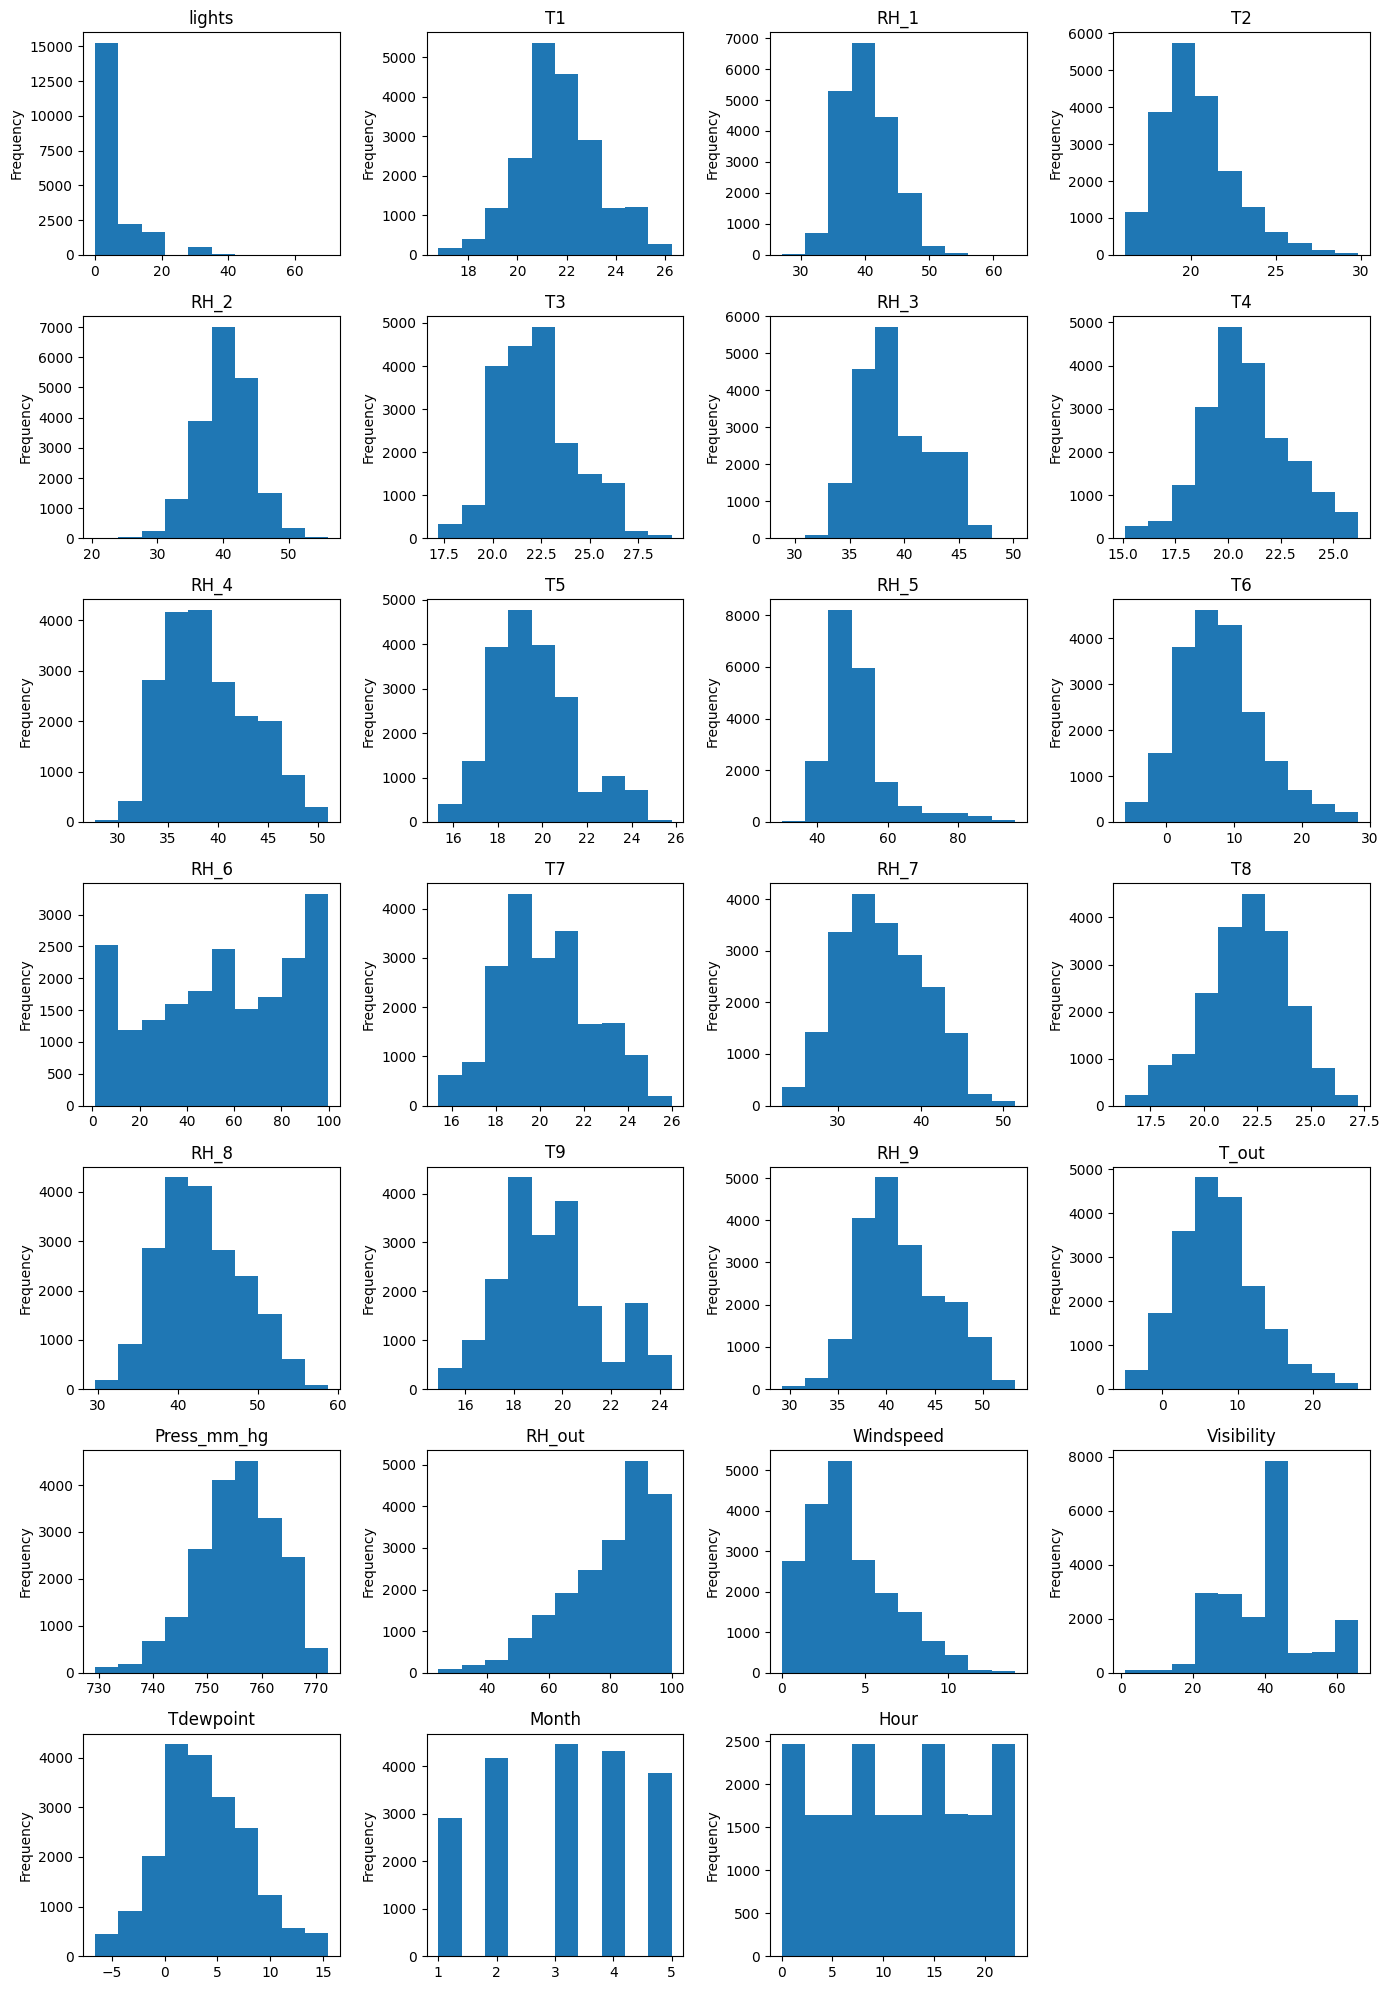

In [ ]:
17. # Distribution plots for all columns
import matplotlib.pyplot as plt

columns = df.select_dtypes(include='number').drop(columns='Appliances').columns

fig, ax = plt.subplots(7, 4, figsize=(14, 20))
ax = ax.flatten()

for i, col in enumerate(columns):
    df[col].plot(kind='hist', bins=10, ax=ax[i])
    ax[i].set_title(col)
    ax[i].grid(False)

for i in range(len(columns), len(ax)):
  ax[i].axis('off')

plt.tight_layout()
plt.show()

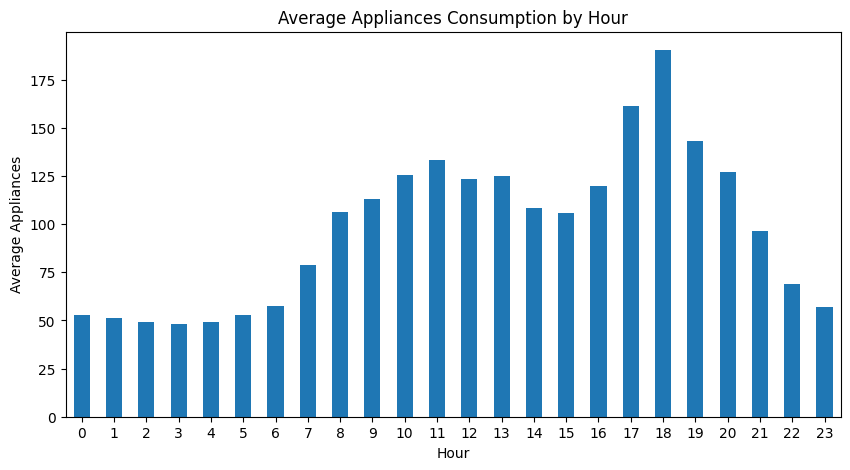

In [ ]:
18. #Bar plot
# Average Appliances consumption by hour
df.groupby('Hour')['Appliances'].mean().plot(kind='bar', figsize=(10,5))

plt.title('Average Appliances Consumption by Hour')
plt.xlabel('Hour')
plt.ylabel('Average Appliances')
plt.xticks(rotation=0)
plt.show()

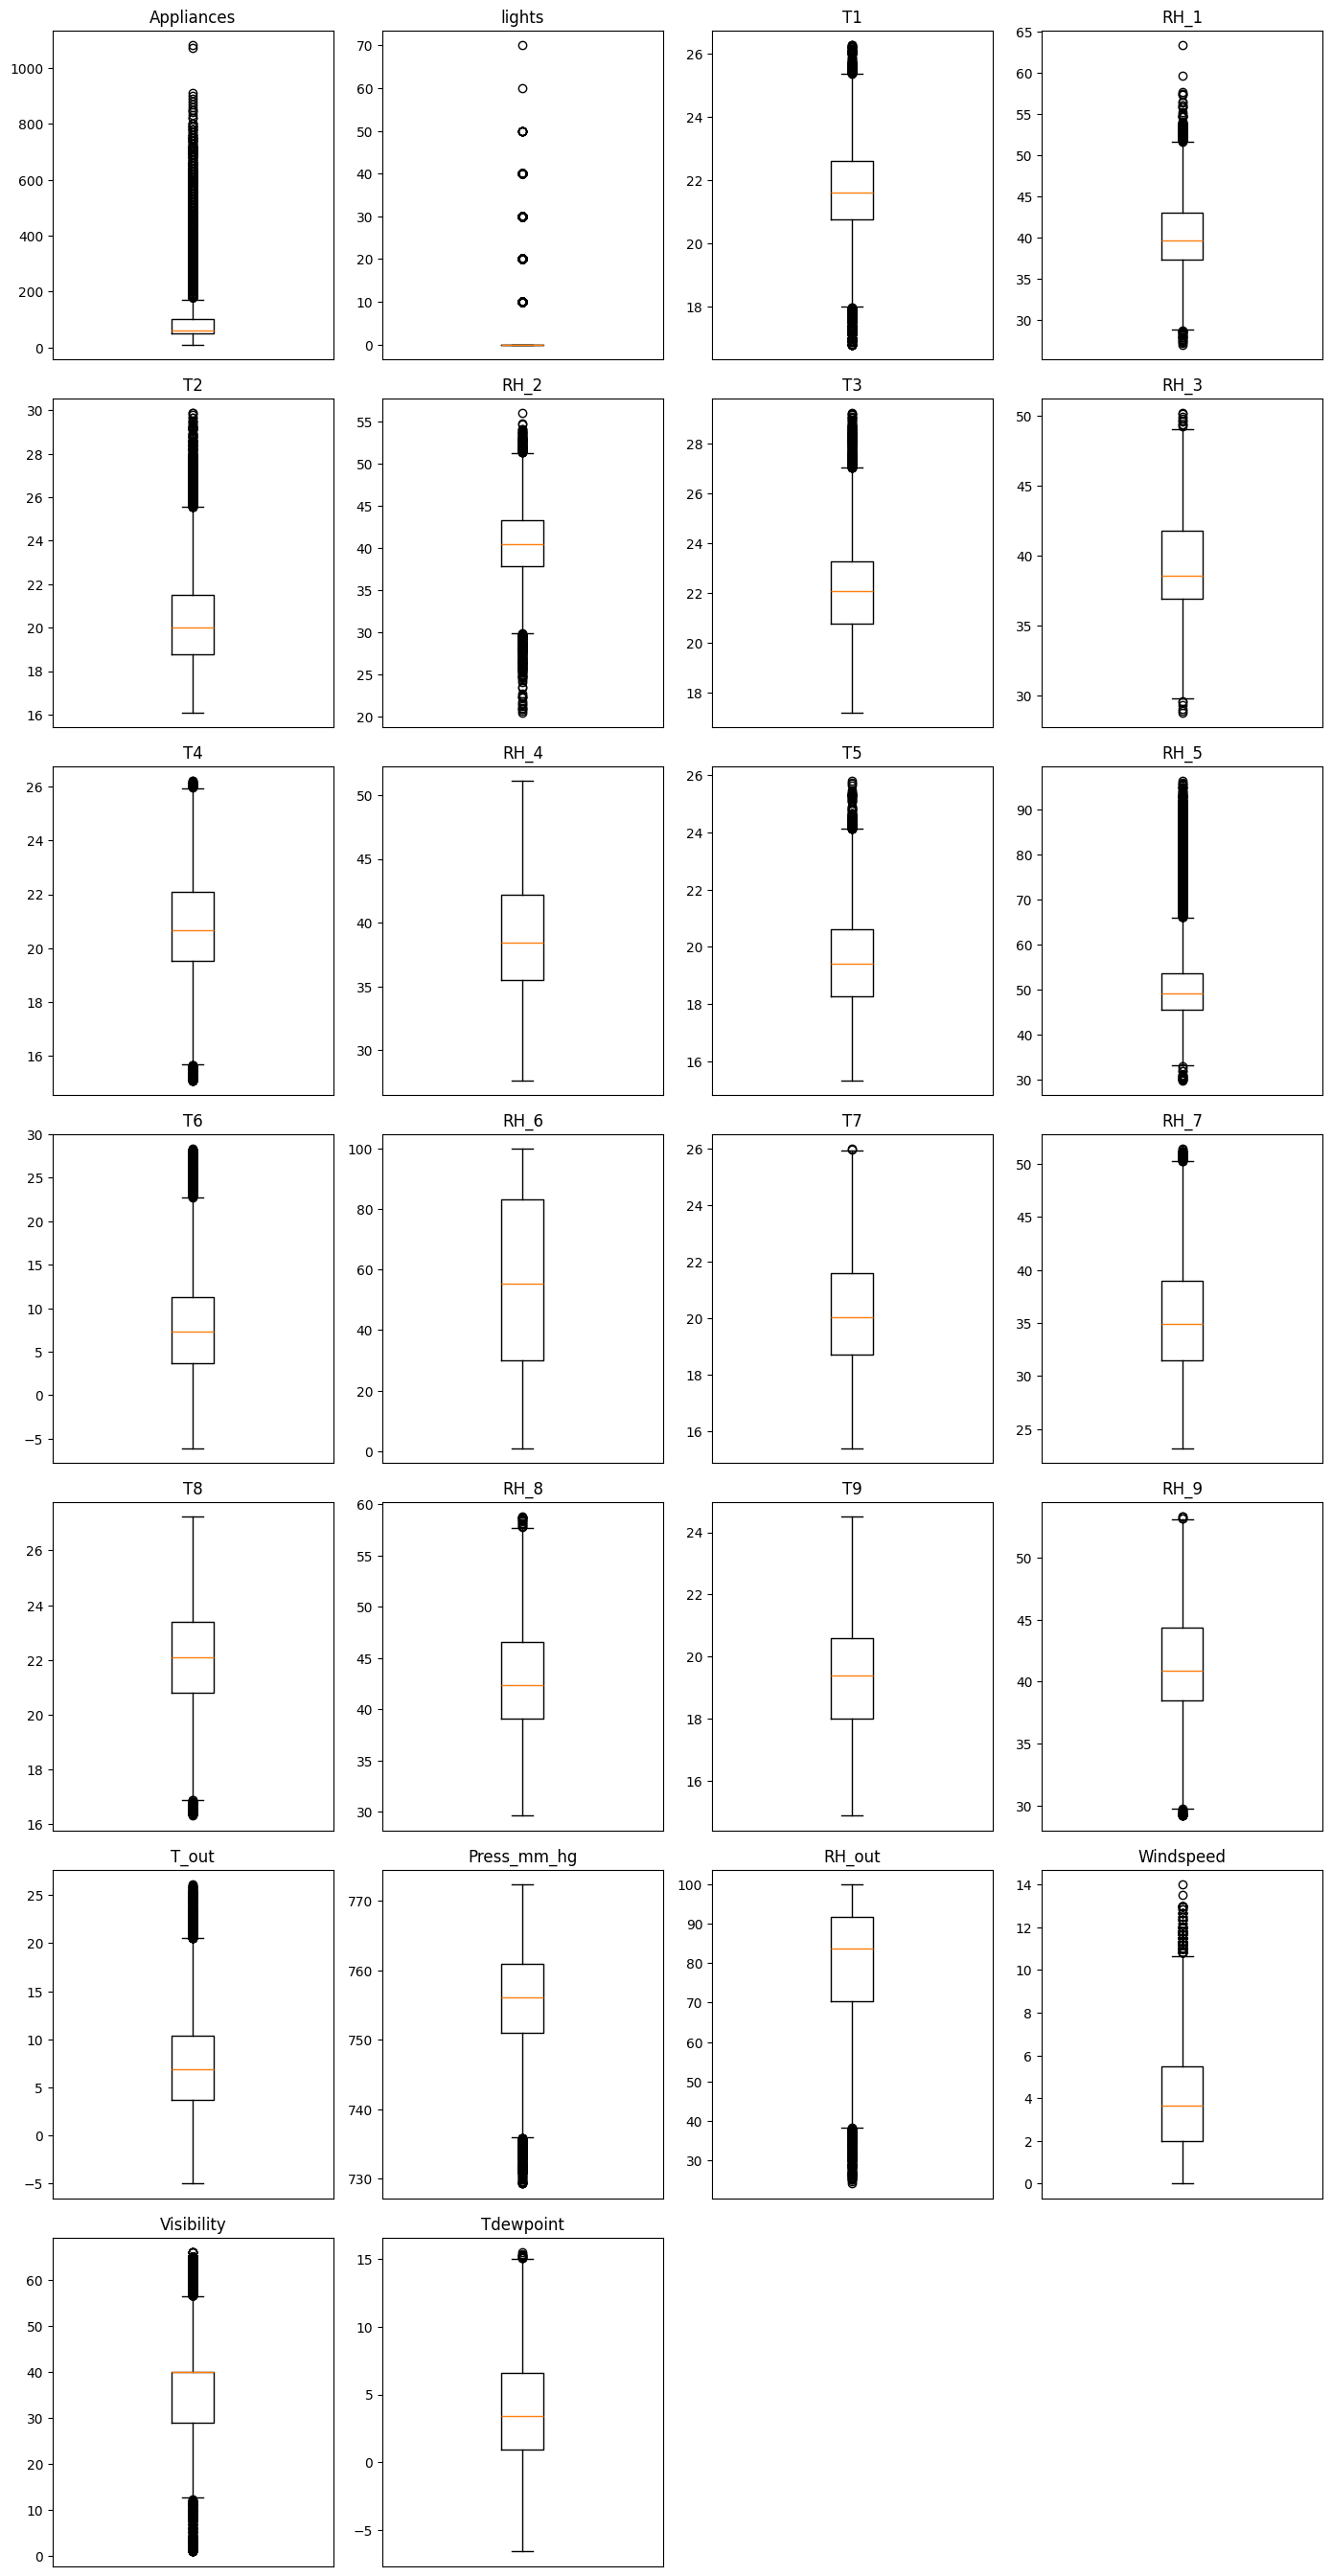

In [ ]:
19. # Box plots for continuous numerical columns

columns = df.select_dtypes(include='number').columns
columns = columns.drop(['Month', 'Hour'])

fig, ax = plt.subplots(7, 4, figsize=(14, 27))
ax = ax.flatten()

for i, col in enumerate(columns):
    ax[i].boxplot(df[col].dropna())
    ax[i].set_title(col)
    ax[i].set_xticks([])

# Remove empty plots
for i in range(len(columns), len(ax)):
    ax[i].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
20. # Check number of outliers in each column

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]

    print(col, ":", len(outliers))

Appliances : 2138
lights : 4483
T1 : 515
RH_1 : 146
T2 : 546
RH_2 : 235
T3 : 217
RH_3 : 15
T4 : 186
RH_4 : 0
T5 : 179
RH_5 : 1330
T6 : 513
RH_6 : 0
T7 : 2
RH_7 : 42
T8 : 71
RH_8 : 17
T9 : 0
RH_9 : 21
T_out : 436
Press_mm_hg : 219
RH_out : 239
Windspeed : 214
Visibility : 2522
Tdewpoint : 10


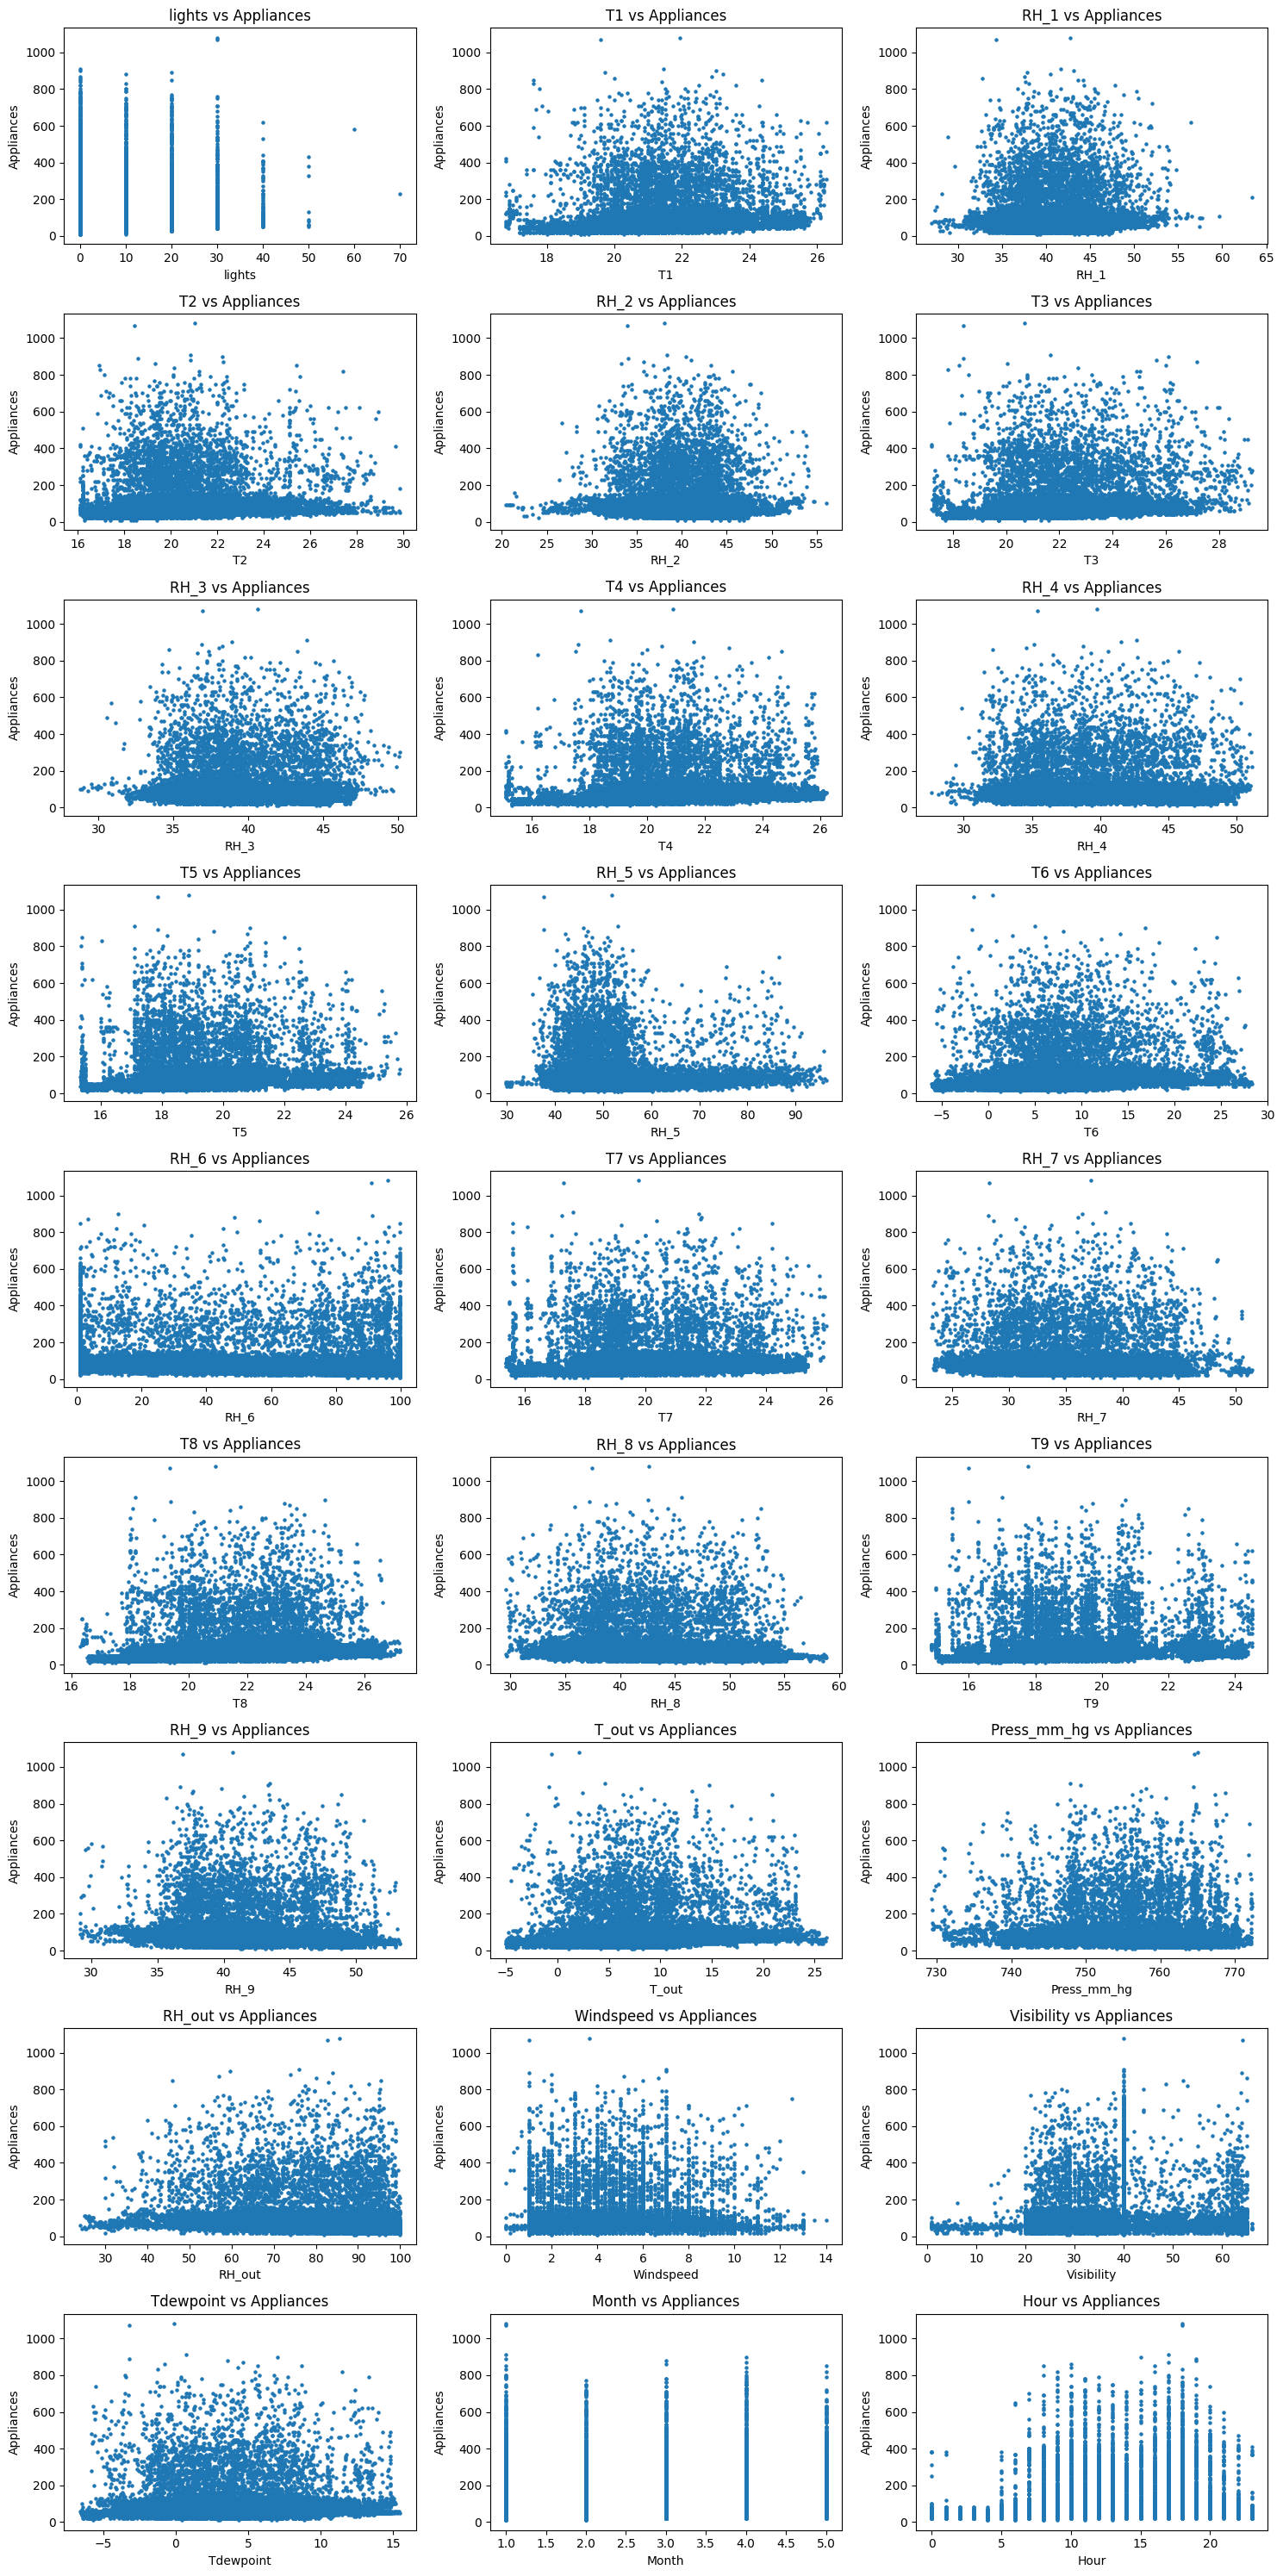

In [ ]:
21. # Scatter plots for all numerical columns vs Appliances

columns = df.select_dtypes(include='number').columns.drop('Appliances')

fig, ax = plt.subplots(9, 3, figsize=(15, 30))
ax = ax.flatten()

for i, col in enumerate(columns):
    ax[i].scatter(df[col], df['Appliances'], s=5)
    ax[i].set_title(col + ' vs Appliances')
    ax[i].set_xlabel(col)
    ax[i].set_ylabel('Appliances')

plt.tight_layout()
plt.show()

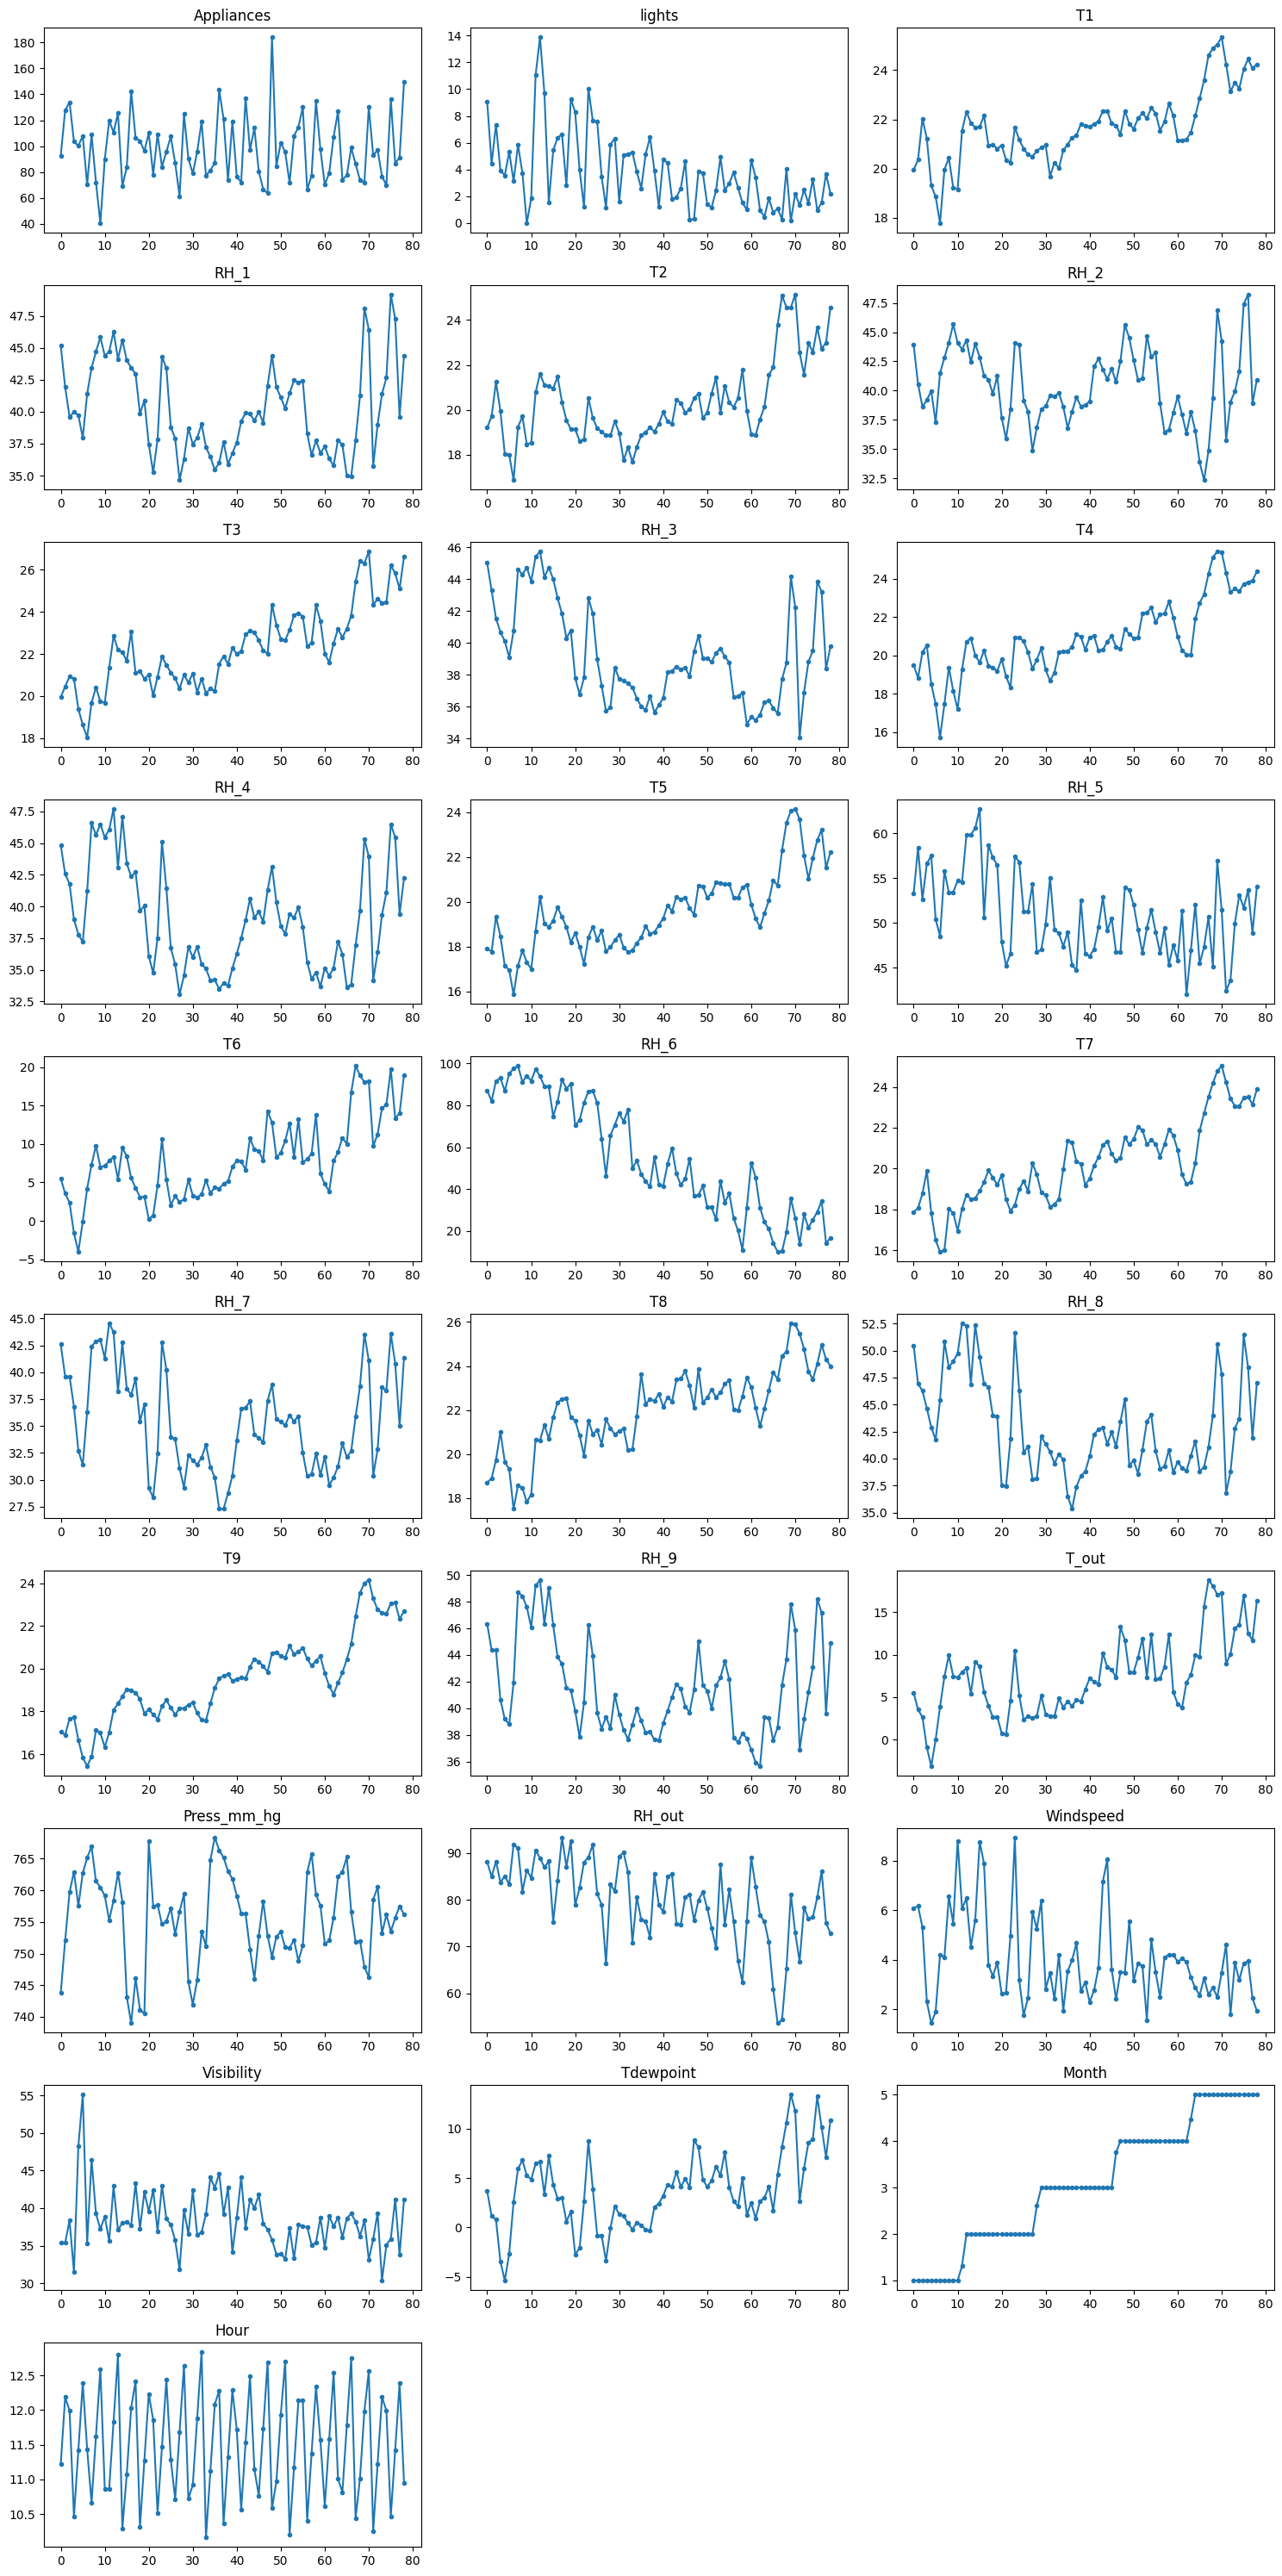

In [ ]:
22. #Line plots for all columns
import matplotlib.pyplot as plt

columns = df.select_dtypes(include='number').loc[:, df.select_dtypes(include='number').nunique() > 2].columns

fig, ax = plt.subplots(10, 3, figsize=(15, 30))
ax = ax.flatten()

for i, col in enumerate(columns):
    df[col].groupby(df.index // 250).mean().plot(ax=ax[i], marker='o', markersize=3)
    ax[i].set_title(col)
    ax[i].set_xlabel('')
    ax[i].set_ylabel('')
    ax[i].grid(False)

for i in range(len(columns), len(ax)):
    ax[i].set_visible(False)

plt.tight_layout()
plt.show()

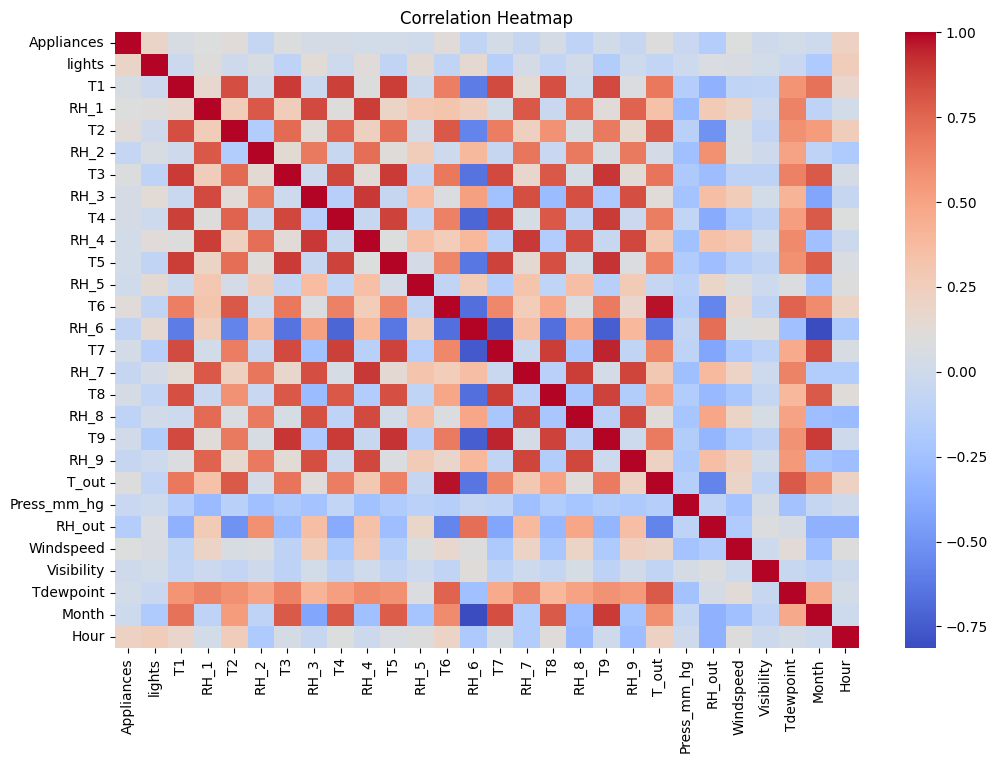

In [ ]:
23. #Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
24. #correlation with target
correlation = df.corr(numeric_only=True)['Appliances']

print(correlation.sort_values(ascending=False))

Appliances     1.000000
Hour           0.216792
lights         0.197278
T2             0.120073
T6             0.117638
T_out          0.099155
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
T1             0.055447
T4             0.040281
T8             0.039572
RH_3           0.036292
T7             0.025801
T5             0.019760
RH_4           0.016965
Tdewpoint      0.015353
T9             0.010010
RH_5           0.006955
Visibility     0.000230
Month         -0.011606
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282
Name: Appliances, dtype: float64


In [ ]:
25. #VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# Separate features and target
X = df.drop('Appliances', axis=1)

# Add constant
X_vif = sm.add_constant(X)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort by VIF
vif = vif.sort_values('VIF', ascending=False)

print(vif)

        Feature         VIF
20        T_out  155.579227
25    Tdewpoint   87.999757
22       RH_out   52.857398
12           T6   34.399877
18           T9   31.986125
4            T2   28.824525
5          RH_2   21.916214
2            T1   20.119732
14           T7   17.826375
9          RH_4   17.719604
3          RH_1   16.232966
26        Month   12.326878
13         RH_6   12.246497
7          RH_3   10.990517
15         RH_7   10.832812
10           T5   10.605001
6            T3   10.225580
8            T4    9.852003
17         RH_8    9.336350
16           T8    8.146515
19         RH_9    6.941726
27         Hour    2.128701
23    Windspeed    1.646674
21  Press_mm_hg    1.409773
11         RH_5    1.399059
1        lights    1.300544
24   Visibility    1.042659
0         const    1.000000


In [ ]:
26. # Check correlation among high-VIF features
high_vif_features = [
    'T_out', 'Tdewpoint', 'RH_out', 'T6', 'T9',
    'T2', 'RH_2', 'T1', 'T7', 'RH_4', 'RH_1'
]

corr = df[high_vif_features].corr()

print(corr.round(2))

           T_out  Tdewpoint  RH_out    T6    T9    T2  RH_2    T1    T7  RH_4  \
T_out       1.00       0.79   -0.57  0.97  0.67  0.79  0.03  0.68  0.63  0.29   
Tdewpoint   0.79       1.00    0.04  0.76  0.58  0.58  0.50  0.57  0.47  0.62   
RH_out     -0.57       0.04    1.00 -0.57 -0.32 -0.51  0.58 -0.35 -0.41  0.34   
T6          0.97       0.76   -0.57  1.00  0.67  0.80 -0.01  0.65  0.62  0.26   
T9          0.67       0.58   -0.32  0.67  1.00  0.68  0.05  0.84  0.94 -0.04   
T2          0.79       0.58   -0.51  0.80  0.68  1.00 -0.17  0.84  0.66  0.23   
RH_2        0.03       0.50    0.58 -0.01  0.05 -0.17  1.00 -0.00 -0.05  0.72   
T1          0.68       0.57   -0.35  0.65  0.84  0.84 -0.00  1.00  0.84  0.10   
T7          0.63       0.47   -0.41  0.62  0.94  0.66 -0.05  0.84  1.00 -0.13   
RH_4        0.29       0.62    0.34  0.26 -0.04  0.23  0.72  0.10 -0.13  1.00   
RH_1        0.34       0.64    0.27  0.32  0.12  0.27  0.80  0.16  0.02  0.88   

           RH_1  
T_out    

In [ ]:
27. # Remove highly correlated feature
df = df.drop('T_out', axis=1)

In [ ]:
28. # Calculate VIF after feature removal
X = df.drop('Appliances', axis=1)

# Add constant
X_vif = sm.add_constant(X)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort by VIF
vif = vif.sort_values('VIF', ascending=False)

print(vif)

        Feature        VIF
18           T9  31.553083
4            T2  28.436223
12           T6  26.663681
5          RH_2  21.674016
24    Tdewpoint  21.074323
2            T1  19.781267
14           T7  17.732407
9          RH_4  17.718694
3          RH_1  16.183805
25        Month  11.636101
7          RH_3  10.909859
15         RH_7  10.828703
13         RH_6  10.735443
10           T5  10.419889
21       RH_out  10.333935
6            T3  10.211903
8            T4   9.851590
17         RH_8   9.261872
16           T8   8.143256
19         RH_9   6.927430
26         Hour   2.128315
22    Windspeed   1.625941
20  Press_mm_hg   1.409773
11         RH_5   1.395601
1        lights   1.300393
23   Visibility   1.040003
0         const   1.000000


In [ ]:
29. # Remove highly correlated feature
df = df.drop('T9', axis=1)

In [ ]:
30. # Calculate VIF after feature removal
X = df.drop('Appliances', axis=1)

# Add constant
X_vif = sm.add_constant(X)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort by VIF
vif = vif.sort_values('VIF', ascending=False)

print(vif)

        Feature        VIF
4            T2  27.562733
12           T6  26.534131
23    Tdewpoint  21.069848
5          RH_2  20.944896
2            T1  19.093483
9          RH_4  17.687961
3          RH_1  16.144651
14           T7  12.638453
24        Month  10.791410
7          RH_3  10.778624
13         RH_6  10.731190
15         RH_7  10.324215
20       RH_out  10.130438
6            T3   9.889507
10           T5   9.474202
8            T4   9.463999
17         RH_8   9.252726
16           T8   8.029847
18         RH_9   6.854947
25         Hour   2.077562
21    Windspeed   1.620246
19  Press_mm_hg   1.383043
11         RH_5   1.382075
1        lights   1.275975
22   Visibility   1.039890
0         const   1.000000


In [ ]:
31. # Remove highly correlated feature
df = df.drop('T2', axis=1)

In [ ]:
32. # Calculate VIF after feature removal
X = df.drop('Appliances', axis=1)

# Add constant
X_vif = sm.add_constant(X)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort by VIF
vif = vif.sort_values('VIF', ascending=False)

print(vif)

        Feature        VIF
11           T6  23.929679
22    Tdewpoint  20.677225
8          RH_4  16.485827
13           T7  12.636296
2            T1  12.100009
23        Month  10.784669
12         RH_6  10.722290
6          RH_3  10.613491
3          RH_1  10.570046
14         RH_7  10.301617
5            T3   9.877032
19       RH_out   9.721585
9            T5   9.411777
16         RH_8   9.172002
7            T4   8.980295
15           T8   8.022754
17         RH_9   6.848283
4          RH_2   6.675193
24         Hour   2.077542
20    Windspeed   1.614772
18  Press_mm_hg   1.381850
10         RH_5   1.378629
1        lights   1.262064
21   Visibility   1.039679
0         const   1.000000


In [ ]:
33. # Check correlation of T6 with remaining temperature features

temperature_features = ['T1', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8']

print(df[temperature_features].corr().round(2))

      T1    T3    T4    T5    T6    T7    T8
T1  1.00  0.89  0.88  0.89  0.65  0.84  0.83
T3  0.89  1.00  0.85  0.89  0.69  0.85  0.80
T4  0.88  0.85  1.00  0.87  0.65  0.88  0.80
T5  0.89  0.89  0.87  1.00  0.63  0.87  0.82
T6  0.65  0.69  0.65  0.63  1.00  0.62  0.48
T7  0.84  0.85  0.88  0.87  0.62  1.00  0.88
T8  0.83  0.80  0.80  0.82  0.48  0.88  1.00


In [ ]:
34. # Remove highly multicollinear feature
df = df.drop('T6', axis=1)

In [ ]:
35. # Calculate VIF after feature removal
X = df.drop('Appliances', axis=1)

# Add constant
X_vif = sm.add_constant(X)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort by VIF
vif = vif.sort_values('VIF', ascending=False)

print(vif)

        Feature        VIF
8          RH_4  16.171312
12           T7  12.629043
2            T1  12.054133
22        Month  10.784506
6          RH_3  10.565747
13         RH_7  10.301592
3          RH_1  10.226221
11         RH_6  10.167114
5            T3   9.846567
9            T5   9.411501
15         RH_8   9.050660
7            T4   8.978425
14           T8   7.966212
16         RH_9   6.840727
21    Tdewpoint   6.671319
4          RH_2   5.660204
18       RH_out   5.058784
23         Hour   2.041829
19    Windspeed   1.591985
10         RH_5   1.377521
17  Press_mm_hg   1.352251
1        lights   1.261968
20   Visibility   1.038961
0         const   1.000000


In [ ]:
36. # Remove highly multicollinear feature
df = df.drop('RH_4', axis=1)

In [ ]:
37. # Calculate VIF after feature removal
X = df.drop('Appliances', axis=1)

# Add constant
X_vif = sm.add_constant(X)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort by VIF
vif = vif.sort_values('VIF', ascending=False)

print(vif)

        Feature        VIF
11           T7  12.443890
2            T1  11.552430
21        Month  10.587063
10         RH_6  10.165718
6          RH_3  10.067642
5            T3   9.801053
12         RH_7   9.694080
3          RH_1   9.160244
8            T5   9.061884
14         RH_8   8.988364
7            T4   8.109196
13           T8   7.966143
15         RH_9   6.561109
20    Tdewpoint   5.918270
4          RH_2   5.655497
17       RH_out   5.045047
22         Hour   2.025861
18    Windspeed   1.583654
9          RH_5   1.377362
16  Press_mm_hg   1.344206
1        lights   1.244264
19   Visibility   1.036596
0         const   1.000000


In [ ]:
38. # Remove highly multicollinear feature
df = df.drop('T7', axis=1)

In [ ]:
39. # Calculate VIF after feature removal
X = df.drop('Appliances', axis=1)

# Add constant
X_vif = sm.add_constant(X)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort by VIF
vif = vif.sort_values('VIF', ascending=False)

print(vif)

        Feature        VIF
2            T1  11.521200
20        Month  10.565337
10         RH_6  10.110198
6          RH_3  10.007234
5            T3   9.752810
3          RH_1   9.157281
8            T5   8.652900
11         RH_7   8.644582
13         RH_8   7.536410
7            T4   7.327261
14         RH_9   6.298755
19    Tdewpoint   5.887645
12           T8   5.840834
4          RH_2   5.629714
16       RH_out   4.968610
21         Hour   1.993988
17    Windspeed   1.583046
9          RH_5   1.370624
15  Press_mm_hg   1.341228
1        lights   1.222149
18   Visibility   1.035625
0         const   1.000000


In [ ]:
40. # Remove highly multicollinear feature
df = df.drop('T1', axis=1)

In [ ]:
41. # Calculate VIF after feature removal
X = df.drop('Appliances', axis=1)

# Add constant
X_vif = sm.add_constant(X)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort by VIF
vif = vif.sort_values('VIF', ascending=False)

print(vif)

        Feature        VIF
19        Month  10.332808
9          RH_6  10.001387
5          RH_3   9.808274
2          RH_1   8.942110
10         RH_7   8.573366
7            T5   8.074535
4            T3   7.697648
12         RH_8   7.523512
6            T4   6.583559
13         RH_9   6.292785
18    Tdewpoint   5.801955
3          RH_2   5.343814
11           T8   4.972470
15       RH_out   4.968543
20         Hour   1.884996
16    Windspeed   1.577083
8          RH_5   1.369042
14  Press_mm_hg   1.335513
1        lights   1.222134
17   Visibility   1.035276
0         const   1.000000


In [ ]:
42. # Remove highly multicollinear feature
df = df.drop('Month', axis=1)

In [ ]:
43. # Calculate VIF after removing Month
X = df.drop('Appliances', axis=1)

# Add constant
X_vif = sm.add_constant(X)

# Calculate VIF
vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort by VIF
vif = vif.sort_values('VIF', ascending=False)

print(vif)

        Feature       VIF
5          RH_3  9.404810
2          RH_1  8.938087
10         RH_7  8.441365
9          RH_6  8.060233
7            T5  7.796751
4            T3  7.538122
12         RH_8  7.520537
6            T4  6.522449
13         RH_9  6.236094
3          RH_2  5.292261
11           T8  4.955218
18    Tdewpoint  4.954611
15       RH_out  4.781028
19         Hour  1.795732
16    Windspeed  1.513814
8          RH_5  1.364559
14  Press_mm_hg  1.319504
1        lights  1.216002
17   Visibility  1.034546
0         const  1.000000


In [ ]:
44. # Train-test split
from sklearn.model_selection import train_test_split

# Regression algorithms
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR

# Feature scaling
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

# Actual vs Predicted visualization
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
45. # Separate input features and target variable
X = df.drop('Appliances', axis=1)
y = df['Appliances']

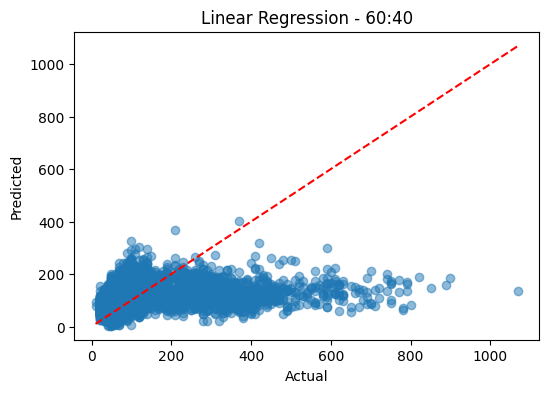

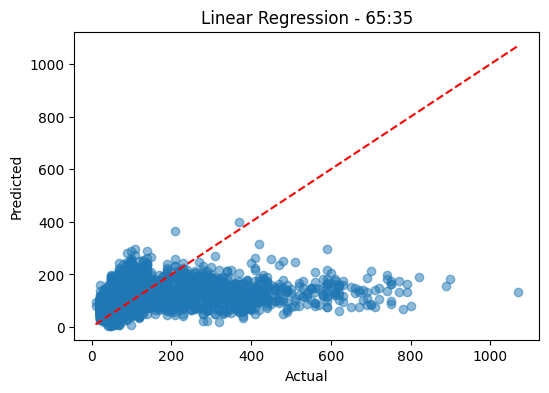

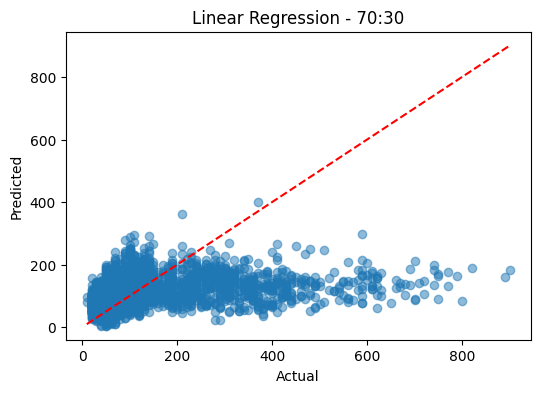

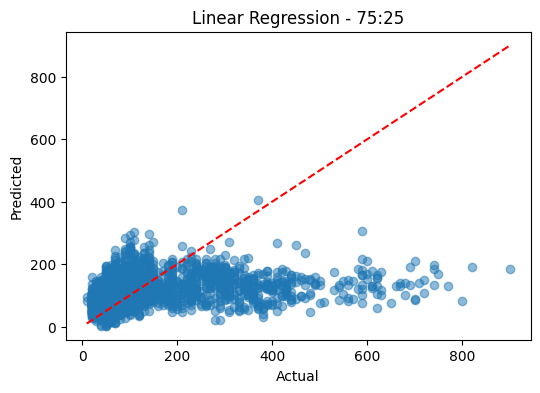

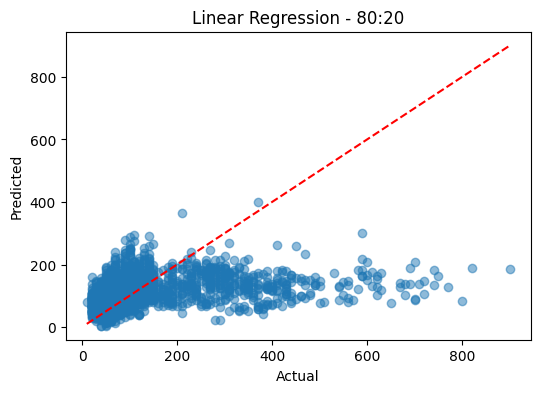

,Split,RMSE,MAE,MAPE,R²
0,60:40,96.508376,54.281909,61.534351,0.136798
1,65:35,96.481755,54.294423,61.955710,0.138347
2,70:30,93.681470,53.635694,62.747899,0.148157
3,75:25,92.505395,53.482176,63.226081,0.138578
4,80:20,92.165579,53.234869,63.409114,0.151153


In [ ]:
46. # Linear Regression - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred)*100,
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Linear Regression - {split_name}")
    plt.show()

linear_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(linear_results)

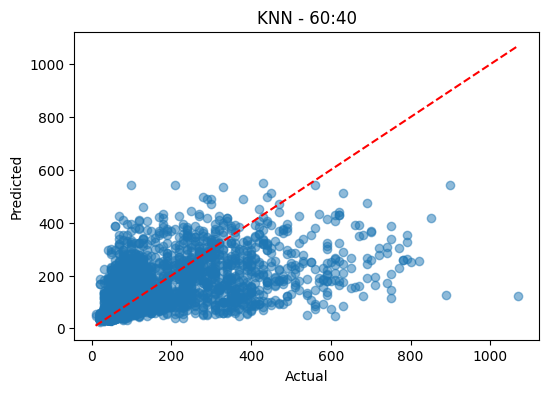

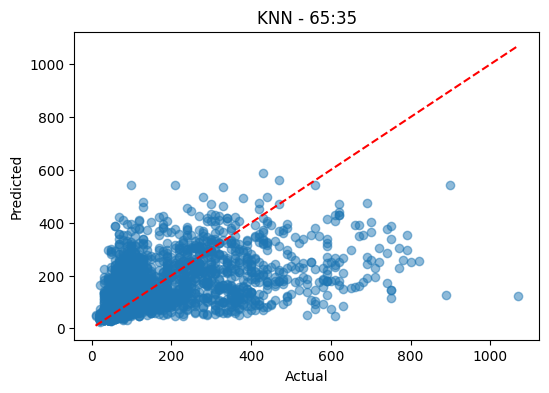

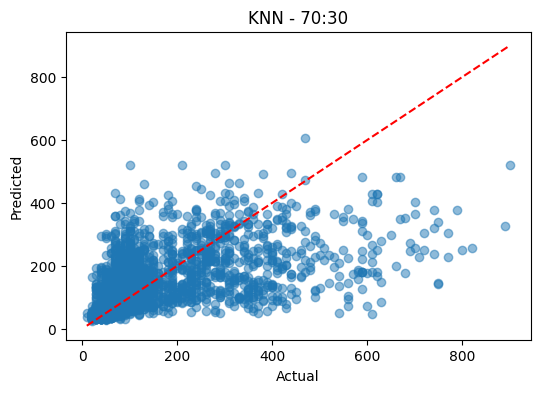

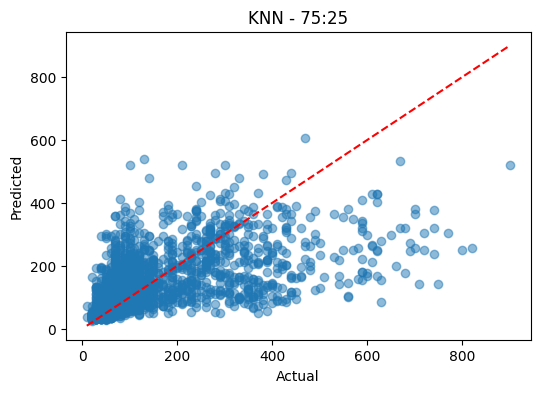

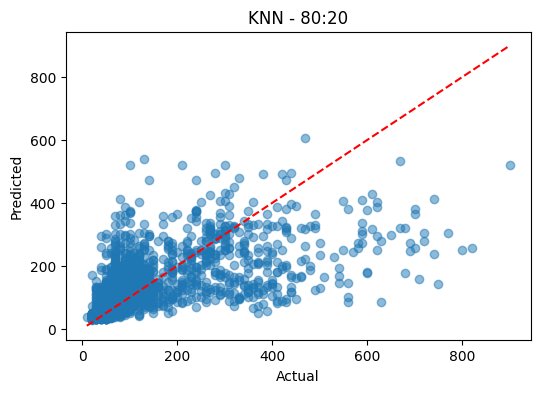

,Split,RMSE,MAE,MAPE,R²
0,60:40,79.914659,37.515328,34.711980,0.408118
1,65:35,80.082380,37.088882,34.281642,0.406370
2,70:30,76.172477,35.668637,33.650579,0.436818
3,75:25,74.277850,34.673287,32.893178,0.444607
4,80:20,73.559464,34.210793,32.718392,0.459284


In [ ]:
47. # KNN Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = KNeighborsRegressor(n_neighbors=5)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred)*100,
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"KNN - {split_name}")
    plt.show()

knn_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(knn_results)

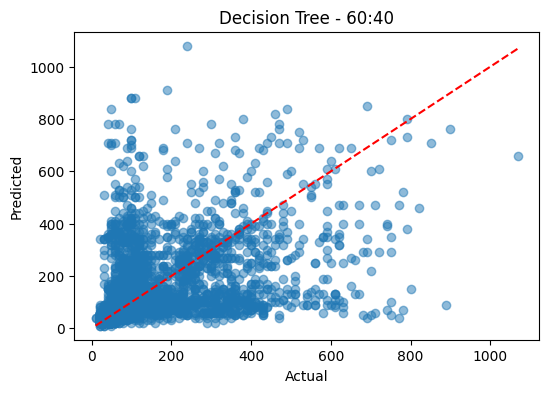

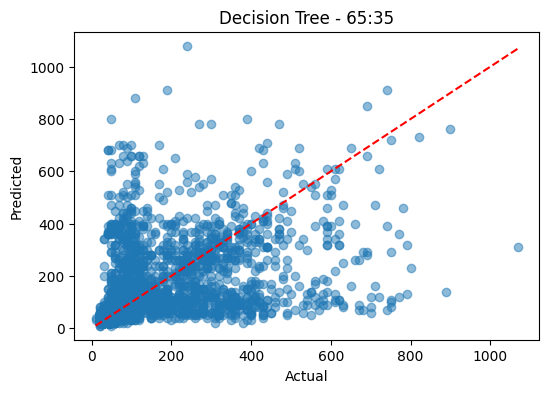

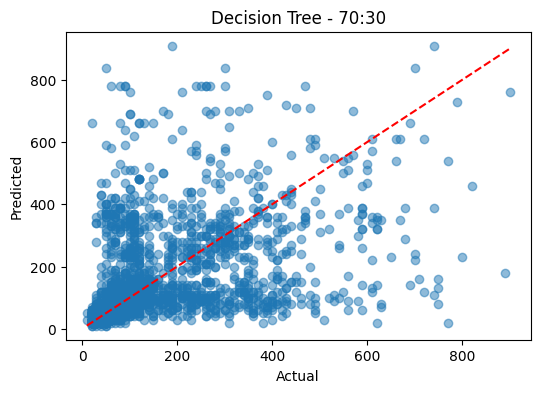

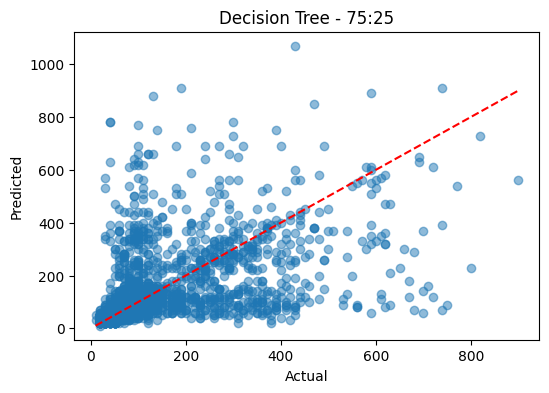

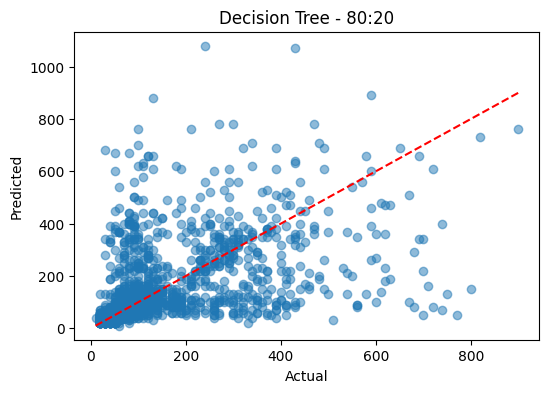

,Split,RMSE,MAE,MAPE,R²
0,60:40,98.170431,41.544211,38.254337,0.106811
1,65:35,96.889523,40.677475,37.648193,0.131048
2,70:30,95.946735,40.179024,37.711481,0.106463
3,75:25,91.624531,37.843535,35.365444,0.154905
4,80:20,93.084410,37.968077,35.742698,0.134143


In [ ]:
48. # Decision Tree Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = DecisionTreeRegressor(random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred)*100,
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Decision Tree - {split_name}")
    plt.show()

decision_tree_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(decision_tree_results)

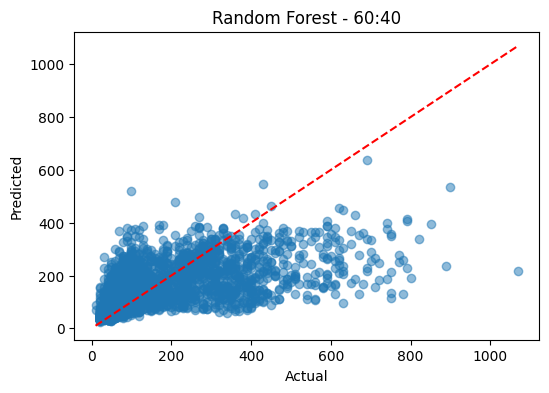

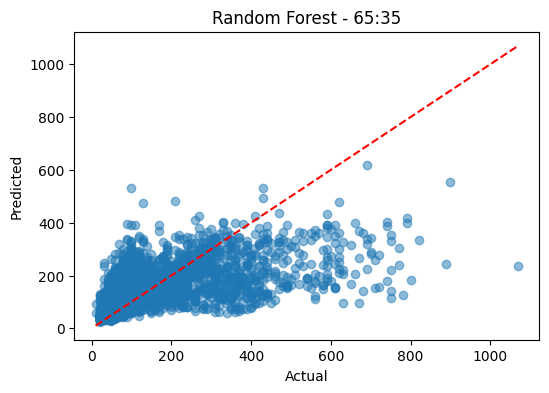

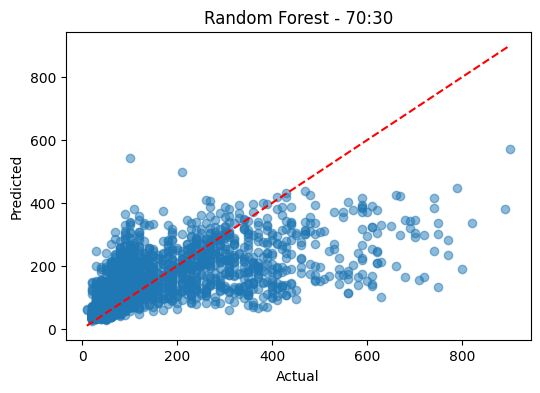

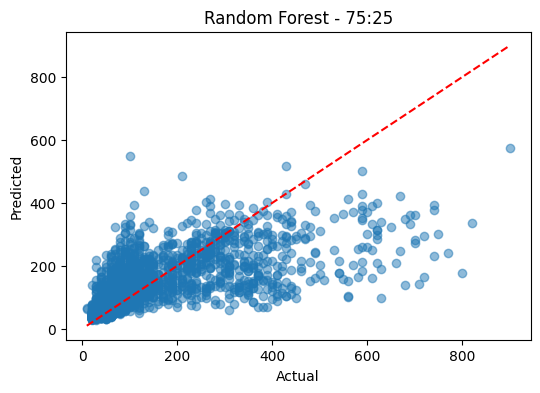

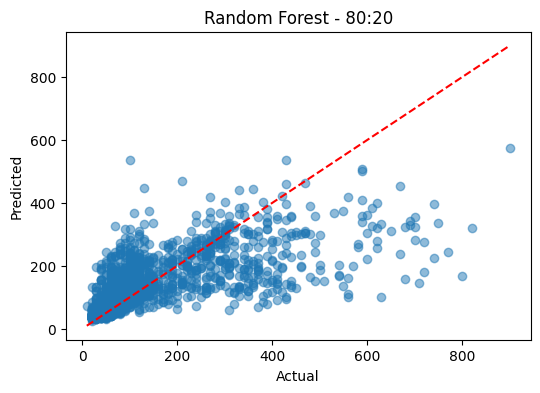

,Split,RMSE,MAE,MAPE,R²
0,60:40,74.722069,35.608144,34.823316,0.482536
1,65:35,74.383127,35.227153,34.380802,0.487857
2,70:30,70.560502,33.828901,34.017085,0.516746
3,75:25,68.480887,32.689747,32.954996,0.527914
4,80:20,67.472187,31.954439,32.514638,0.545073


In [ ]:
49. # Random Forest Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred)*100,
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Random Forest - {split_name}")
    plt.show()

random_forest_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(random_forest_results)

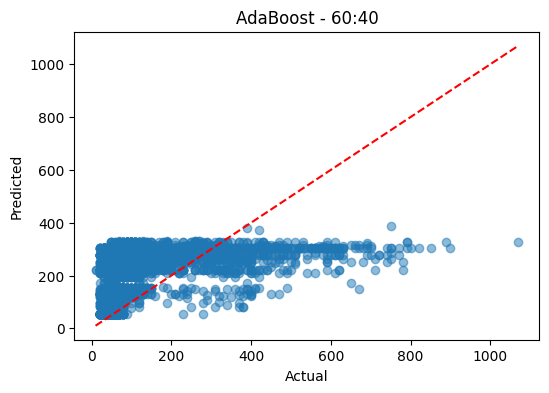

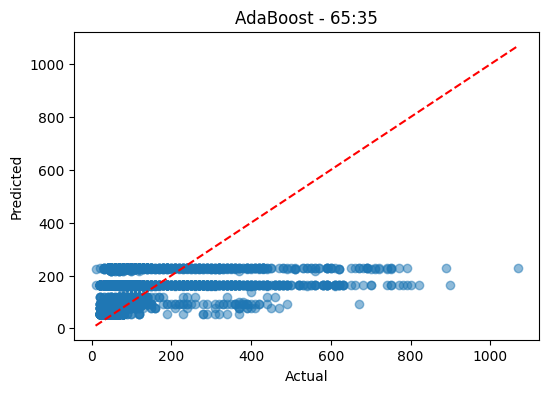

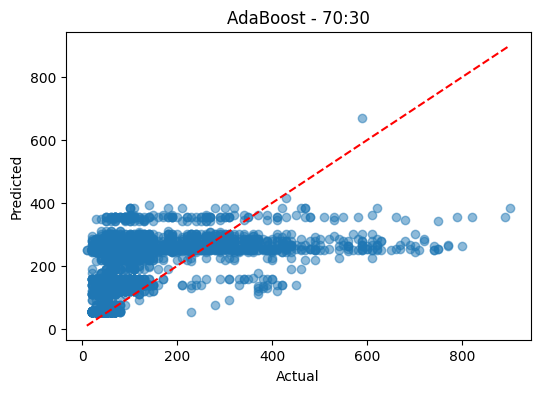

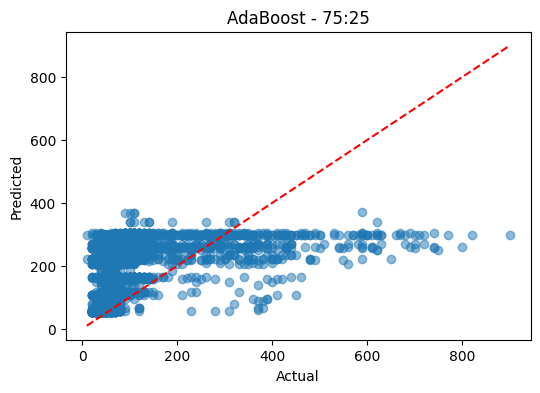

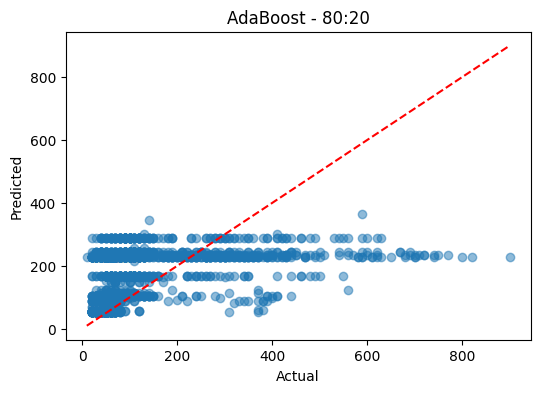

,Split,RMSE,MAE,MAPE,R²
0,60:40,147.067491,116.753942,176.743334,-1.004544
1,65:35,102.494543,68.826645,93.004701,0.027603
2,70:30,142.288029,113.182076,176.585353,-0.965120
3,75:25,138.565977,107.488300,165.720293,-0.932837
4,80:20,122.272660,91.351996,137.338814,-0.494001


In [ ]:
50. # AdaBoost Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = AdaBoostRegressor(
        n_estimators=100,
        random_state=42
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred)*100,
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"AdaBoost - {split_name}")
    plt.show()

adaboost_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(adaboost_results)

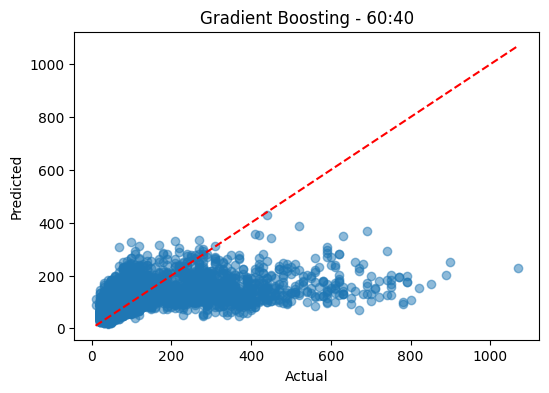

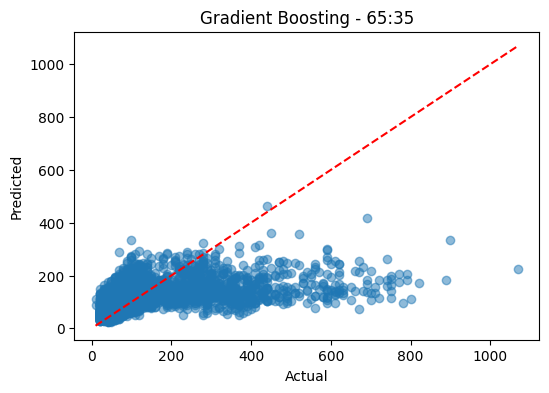

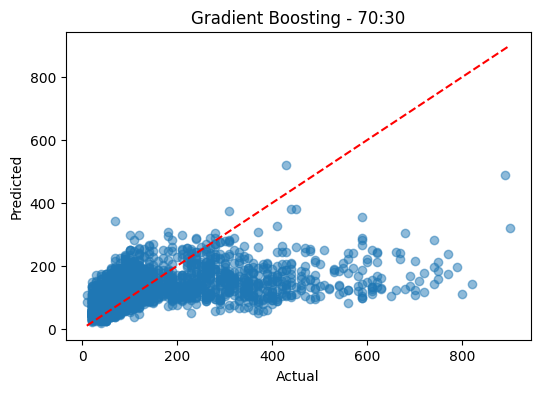

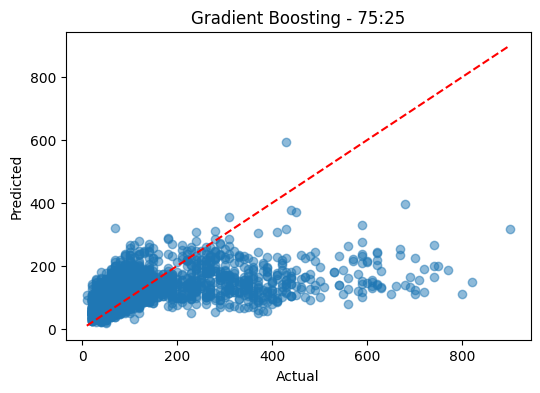

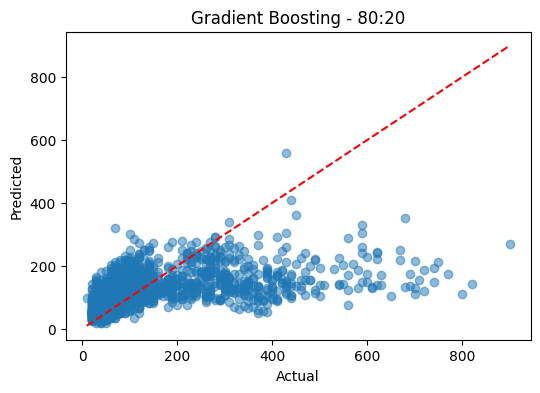

,Split,RMSE,MAE,MAPE,R²
0,60:40,88.205948,46.528603,49.780218,0.278929
1,65:35,88.060714,46.581934,50.356546,0.282195
2,70:30,85.298690,46.030600,51.483556,0.293785
3,75:25,84.008283,45.836303,51.832258,0.289562
4,80:20,83.995846,45.752164,52.087859,0.294970


In [ ]:
51. # Gradient Boosting Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred)*100,
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Gradient Boosting - {split_name}")
    plt.show()

gradient_boosting_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(gradient_boosting_results)

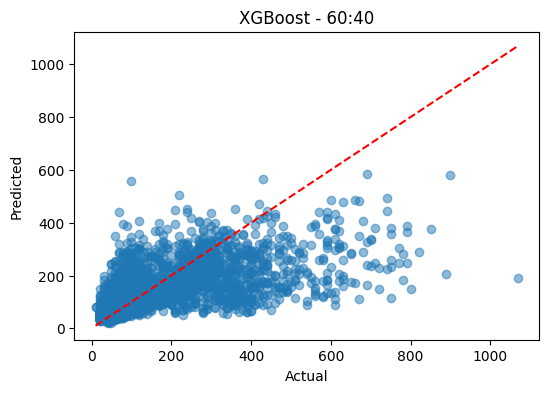

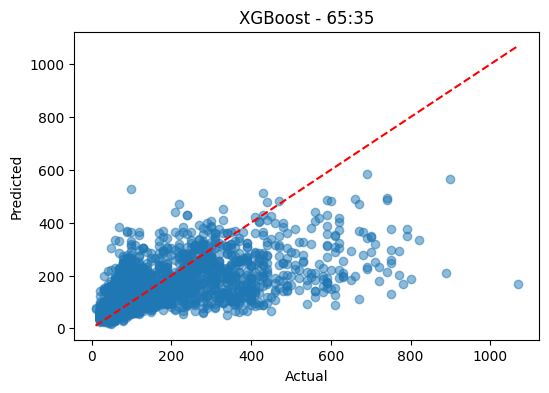

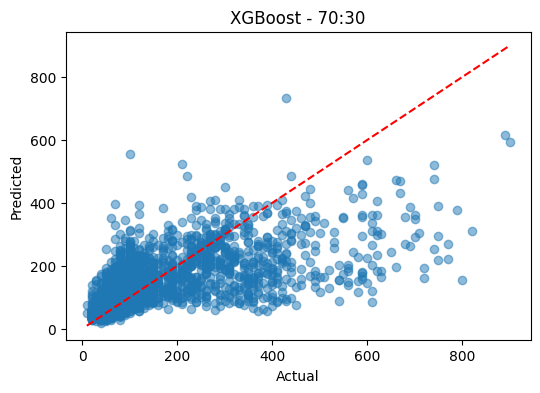

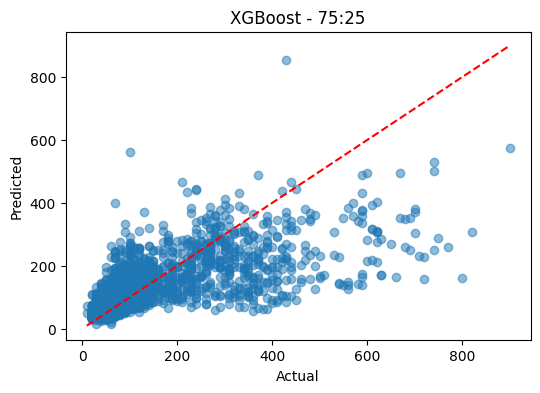

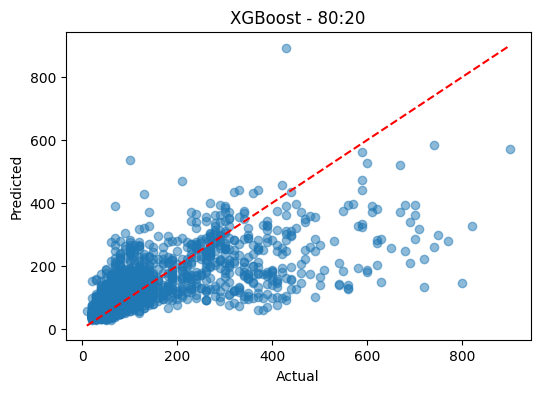

,Split,RMSE,MAE,MAPE,R²
0,60:40,74.283873,36.273453,36.265340,0.488588
1,65:35,73.816641,36.083500,36.276448,0.495628
2,70:30,70.086338,34.827274,36.055249,0.523219
3,75:25,68.118922,33.946590,35.286620,0.532892
4,80:20,68.419222,33.965599,35.736614,0.532213


In [ ]:
52.  # XGBoost Regressor - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    model = XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=2,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred)*100,
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"XGBoost - {split_name}")
    plt.show()

xgboost_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(xgboost_results)

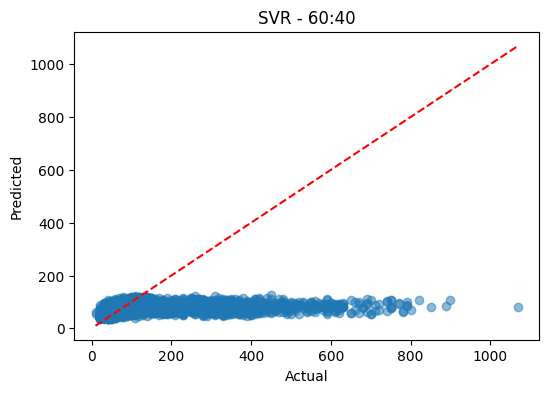

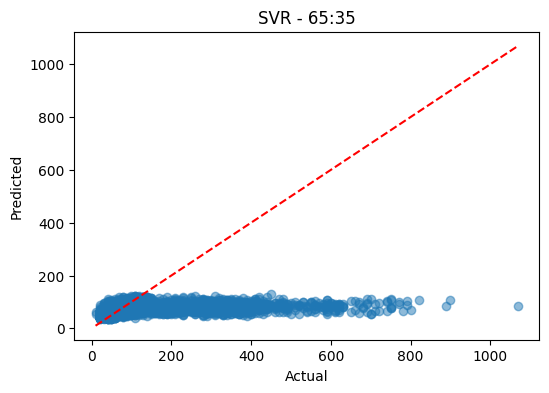

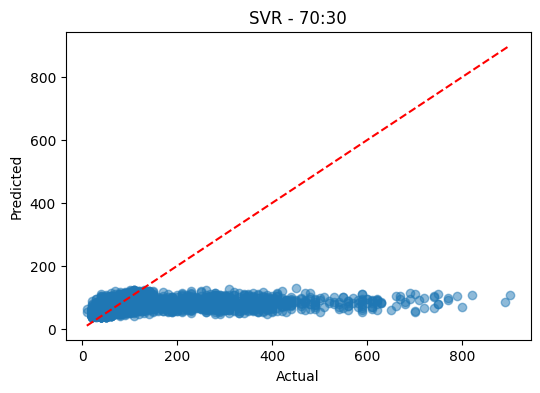

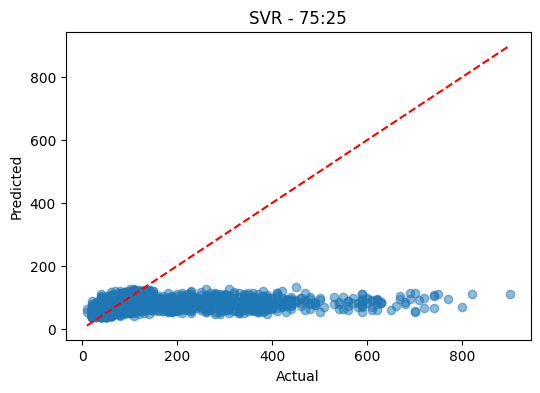

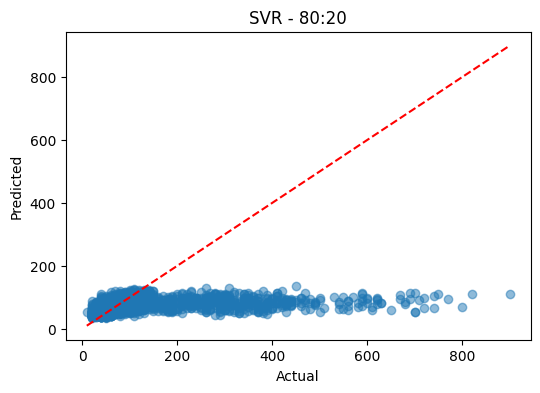

,Split,RMSE,MAE,MAPE,R²
0,60:40,102.895585,43.941358,32.229768,0.018759
1,65:35,102.719125,43.711988,32.198168,0.023337
2,70:30,99.845860,42.711813,32.185647,0.032363
3,75:25,97.710151,41.875276,31.911800,0.038916
4,80:20,97.799579,41.609649,31.719960,0.044202


In [ ]:
53. # Support Vector Regression - 5 Splits
splits = {
    "60:40": 0.40,
    "65:35": 0.35,
    "70:30": 0.30,
    "75:25": 0.25,
    "80:20": 0.20
}

results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = SVR()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append([
        split_name,
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_absolute_error(y_test, y_pred),
        mean_absolute_percentage_error(y_test, y_pred)*100,
        r2_score(y_test, y_pred)
    ])

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"SVR - {split_name}")
    plt.show()

svr_results = pd.DataFrame(
    results,
    columns=["Split", "RMSE", "MAE", "MAPE", "R²"]
)

display(svr_results)

In [ ]:
54.  # All models and splits results
all_results = pd.concat([
    linear_results.assign(Model="Linear Regression"),
    knn_results.assign(Model="KNN"),
    decision_tree_results.assign(Model="Decision Tree"),
    random_forest_results.assign(Model="Random Forest"),
    adaboost_results.assign(Model="AdaBoost"),
    gradient_boosting_results.assign(Model="Gradient Boosting"),
    xgboost_results.assign(Model="XGBoost"),
    svr_results.assign(Model="SVR")
], ignore_index=True)

all_results = all_results[
    ["Model", "Split", "RMSE", "MAE", "MAPE", "R²"]
]

display(all_results)

,Model,Split,RMSE,MAE,MAPE,R²
0,Linear Regression,60:40,96.508376,54.281909,61.534351,0.136798
1,Linear Regression,65:35,96.481755,54.294423,61.955710,0.138347
2,Linear Regression,70:30,93.681470,53.635694,62.747899,0.148157
3,Linear Regression,75:25,92.505395,53.482176,63.226081,0.138578
4,Linear Regression,80:20,92.165579,53.234869,63.409114,0.151153
5,KNN,60:40,79.914659,37.515328,34.711980,0.408118
6,KNN,65:35,80.082380,37.088882,34.281642,0.406370
7,KNN,70:30,76.172477,35.668637,33.650579,0.436818
8,KNN,75:25,74.277850,34.673287,32.893178,0.444607
9,KNN,80:20,73.559464,34.210793,32.718392,0.459284


In [ ]:
55.  # Highest R²
highest = all_results.sort_values("R²", ascending=False).head(1)

display(highest)

,Model,Split,RMSE,MAE,MAPE,R²
19,Random Forest,80:20,67.472187,31.954439,32.514638,0.545073


In [ ]:
56. # ANN Data Preparation & Feature Scaling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Train-test split (80:20)
X_train_ann, X_test_ann, y_train_ann, y_test_ann = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=52
)

# Feature scaling
scaler_ann = StandardScaler()
X_train_ann_scaled = scaler_ann.fit_transform(X_train_ann)
X_test_ann_scaled = scaler_ann.transform(X_test_ann)

# Storage for results and histories
ann_results = []
ann_histories = {}
ann_predictions = {}
ann_models = {}

print("ANN Data preparation complete. Features scaled successfully.")


ANN Data preparation complete. Features scaled successfully.


In [ ]:
# 56.1 ANN Config 1 (Adam - [256, 128, 64, 32, 16] - 500 Epochs)
ann_1 = Sequential()
ann_1.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_1.add(Dense(256, activation='relu'))
    ann_1.add(Dropout(0.1))
    ann_1.add(Dense(128, activation='relu'))
    ann_1.add(Dense(64, activation='relu'))
    ann_1.add(Dense(32, activation='relu'))
    ann_1.add(Dense(16, activation='relu'))
    ann_1.add(Dense(1, activation='linear'))

ann_1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_1 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_1 = ann_1.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=500,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_1,
    verbose=0
)

y_pred_1 = ann_1.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_1 = np.sqrt(mean_squared_error(y_test_ann, y_pred_1))
mae_1 = mean_absolute_error(y_test_ann, y_pred_1)
mape_1 = mean_absolute_percentage_error(y_test_ann, y_pred_1) * 100
r2_1 = r2_score(y_test_ann, y_pred_1)

ann_results.append({
    "Configuration": "ANN Config 1 (Adam)",
    "Optimizer": "Adam",
    "Architecture": "[256, 128, 64, 32, 16]",
    "Epochs": 500,
    "RMSE": rmse_1,
    "MAE": mae_1,
    "MAPE": mape_1,
    "R²": r2_1
})

ann_histories[1] = history_1.history

print("RMSE:", rmse_1)
print("MAE:", mae_1)
print("MAPE:", mape_1)
print("R²:", r2_1)


RMSE: 72.51559301604553
MAE: 33.63844299316406
MAPE: 32.65900909900665
R²: 0.4679308533668518


In [ ]:
# 56.2 ANN Config 2 (Adam - [128, 64, 32, 16] - 1000 Epochs)
ann_2 = Sequential()
ann_2.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_2.add(Dense(128, activation='relu'))
    ann_2.add(Dropout(0.1))
    ann_2.add(Dense(64, activation='relu'))
    ann_2.add(Dense(32, activation='relu'))
    ann_2.add(Dense(16, activation='relu'))
    ann_2.add(Dense(1, activation='linear'))

ann_2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_2 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_2 = ann_2.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=1000,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_2,
    verbose=0
)

y_pred_2 = ann_2.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_2 = np.sqrt(mean_squared_error(y_test_ann, y_pred_2))
mae_2 = mean_absolute_error(y_test_ann, y_pred_2)
mape_2 = mean_absolute_percentage_error(y_test_ann, y_pred_2) * 100
r2_2 = r2_score(y_test_ann, y_pred_2)

ann_results.append({
    "Configuration": "ANN Config 2 (Adam)",
    "Optimizer": "Adam",
    "Architecture": "[128, 64, 32, 16]",
    "Epochs": 1000,
    "RMSE": rmse_2,
    "MAE": mae_2,
    "MAPE": mape_2,
    "R²": r2_2
})

ann_histories[2] = history_2.history

print("RMSE:", rmse_2)
print("MAE:", mae_2)
print("MAPE:", mape_2)
print("R²:", r2_2)


RMSE: 71.205413681124
MAE: 33.852012634277344
MAPE: 32.6889842748642
R²: 0.48698359727859497


In [ ]:
# 56.3 ANN Config 3 (Adam - [128, 64, 32] - 1500 Epochs)
ann_3 = Sequential()
ann_3.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_3.add(Dense(128, activation='relu'))
    ann_3.add(Dropout(0.1))
    ann_3.add(Dense(64, activation='relu'))
    ann_3.add(Dense(32, activation='relu'))
    ann_3.add(Dense(1, activation='linear'))

ann_3.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_3 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_3 = ann_3.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=1500,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_3,
    verbose=0
)

y_pred_3 = ann_3.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_3 = np.sqrt(mean_squared_error(y_test_ann, y_pred_3))
mae_3 = mean_absolute_error(y_test_ann, y_pred_3)
mape_3 = mean_absolute_percentage_error(y_test_ann, y_pred_3) * 100
r2_3 = r2_score(y_test_ann, y_pred_3)

ann_results.append({
    "Configuration": "ANN Config 3 (Adam)",
    "Optimizer": "Adam",
    "Architecture": "[128, 64, 32]",
    "Epochs": 1500,
    "RMSE": rmse_3,
    "MAE": mae_3,
    "MAPE": mape_3,
    "R²": r2_3
})

ann_histories[3] = history_3.history

print("RMSE:", rmse_3)
print("MAE:", mae_3)
print("MAPE:", mape_3)
print("R²:", r2_3)


RMSE: 73.30590270294576
MAE: 36.09172058105469
MAPE: 35.917189717292786
R²: 0.4562702178955078


In [ ]:
# 56.4 ANN Config 4 (Adam - [64, 32, 16] - 2000 Epochs)
ann_4 = Sequential()
ann_4.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_4.add(Dense(64, activation='relu'))
    ann_4.add(Dropout(0.05))
    ann_4.add(Dense(32, activation='relu'))
    ann_4.add(Dense(16, activation='relu'))
    ann_4.add(Dense(1, activation='linear'))

ann_4.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_4 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_4 = ann_4.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=2000,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_4,
    verbose=0
)

y_pred_4 = ann_4.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_4 = np.sqrt(mean_squared_error(y_test_ann, y_pred_4))
mae_4 = mean_absolute_error(y_test_ann, y_pred_4)
mape_4 = mean_absolute_percentage_error(y_test_ann, y_pred_4) * 100
r2_4 = r2_score(y_test_ann, y_pred_4)

ann_results.append({
    "Configuration": "ANN Config 4 (Adam)",
    "Optimizer": "Adam",
    "Architecture": "[64, 32, 16]",
    "Epochs": 2000,
    "RMSE": rmse_4,
    "MAE": mae_4,
    "MAPE": mape_4,
    "R²": r2_4
})

ann_histories[4] = history_4.history

print("RMSE:", rmse_4)
print("MAE:", mae_4)
print("MAPE:", mape_4)
print("R²:", r2_4)


RMSE: 74.5237646922527
MAE: 39.344295501708984
MAPE: 41.78468585014343
R²: 0.4380536675453186


In [ ]:
# 56.5 ANN Config 5 (Adam - [64, 32] - 2500 Epochs)
ann_5 = Sequential()
ann_5.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_5.add(Dense(64, activation='relu'))
    ann_5.add(Dense(32, activation='relu'))
    ann_5.add(Dense(1, activation='linear'))

ann_5.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_5 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_5 = ann_5.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=2500,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_5,
    verbose=0
)

y_pred_5 = ann_5.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_5 = np.sqrt(mean_squared_error(y_test_ann, y_pred_5))
mae_5 = mean_absolute_error(y_test_ann, y_pred_5)
mape_5 = mean_absolute_percentage_error(y_test_ann, y_pred_5) * 100
r2_5 = r2_score(y_test_ann, y_pred_5)

ann_results.append({
    "Configuration": "ANN Config 5 (Adam)",
    "Optimizer": "Adam",
    "Architecture": "[64, 32]",
    "Epochs": 2500,
    "RMSE": rmse_5,
    "MAE": mae_5,
    "MAPE": mape_5,
    "R²": r2_5
})

ann_histories[5] = history_5.history

print("RMSE:", rmse_5)
print("MAE:", mae_5)
print("MAPE:", mape_5)
print("R²:", r2_5)


RMSE: 79.18859756540078
MAE: 45.61777877807617
MAPE: 51.36800408363342
R²: 0.3655015826225281


In [ ]:
# 56.6 ANN Config 6 (SGD - [256, 128, 64, 32, 16] - 500 Epochs)
ann_6 = Sequential()
ann_6.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_6.add(Dense(256, activation='relu'))
    ann_6.add(Dropout(0.1))
    ann_6.add(Dense(128, activation='relu'))
    ann_6.add(Dense(64, activation='relu'))
    ann_6.add(Dense(32, activation='relu'))
    ann_6.add(Dense(16, activation='relu'))
    ann_6.add(Dense(1, activation='linear'))

ann_6.compile(
    optimizer=SGD(learning_rate=0.001, momentum=0.9, clipnorm=1.0),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_6 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_6 = ann_6.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=500,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_6,
    verbose=0
)

y_pred_6 = ann_6.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_6 = np.sqrt(mean_squared_error(y_test_ann, y_pred_6))
mae_6 = mean_absolute_error(y_test_ann, y_pred_6)
mape_6 = mean_absolute_percentage_error(y_test_ann, y_pred_6) * 100
r2_6 = r2_score(y_test_ann, y_pred_6)

ann_results.append({
    "Configuration": "ANN Config 6 (SGD)",
    "Optimizer": "SGD",
    "Architecture": "[256, 128, 64, 32, 16]",
    "Epochs": 500,
    "RMSE": rmse_6,
    "MAE": mae_6,
    "MAPE": mape_6,
    "R²": r2_6
})

ann_histories[6] = history_6.history

print("RMSE:", rmse_6)
print("MAE:", mae_6)
print("MAPE:", mape_6)
print("R²:", r2_6)


RMSE: 73.30150306482467
MAE: 35.49422073364258
MAPE: 34.679484367370605
R²: 0.45633548498153687


In [ ]:
# 56.7 ANN Config 7 (SGD - [128, 64, 32, 16] - 1000 Epochs)
ann_7 = Sequential()
ann_7.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_7.add(Dense(128, activation='relu'))
    ann_7.add(Dropout(0.1))
    ann_7.add(Dense(64, activation='relu'))
    ann_7.add(Dense(32, activation='relu'))
    ann_7.add(Dense(16, activation='relu'))
    ann_7.add(Dense(1, activation='linear'))

ann_7.compile(
    optimizer=SGD(learning_rate=0.001, momentum=0.9, clipnorm=1.0),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_7 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_7 = ann_7.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=1000,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_7,
    verbose=0
)

y_pred_7 = ann_7.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_7 = np.sqrt(mean_squared_error(y_test_ann, y_pred_7))
mae_7 = mean_absolute_error(y_test_ann, y_pred_7)
mape_7 = mean_absolute_percentage_error(y_test_ann, y_pred_7) * 100
r2_7 = r2_score(y_test_ann, y_pred_7)

ann_results.append({
    "Configuration": "ANN Config 7 (SGD)",
    "Optimizer": "SGD",
    "Architecture": "[128, 64, 32, 16]",
    "Epochs": 1000,
    "RMSE": rmse_7,
    "MAE": mae_7,
    "MAPE": mape_7,
    "R²": r2_7
})

ann_histories[7] = history_7.history

print("RMSE:", rmse_7)
print("MAE:", mae_7)
print("MAPE:", mape_7)
print("R²:", r2_7)


RMSE: 73.02418263835618
MAE: 34.98105239868164
MAPE: 34.213441610336304
R²: 0.46044135093688965


In [ ]:
# 56.8 ANN Config 8 (SGD - [128, 64, 32] - 1500 Epochs)
ann_8 = Sequential()
ann_8.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_8.add(Dense(128, activation='relu'))
    ann_8.add(Dropout(0.1))
    ann_8.add(Dense(64, activation='relu'))
    ann_8.add(Dense(32, activation='relu'))
    ann_8.add(Dense(1, activation='linear'))

ann_8.compile(
    optimizer=SGD(learning_rate=0.001, momentum=0.9, clipnorm=1.0),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_8 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_8 = ann_8.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=1500,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_8,
    verbose=0
)

y_pred_8 = ann_8.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_8 = np.sqrt(mean_squared_error(y_test_ann, y_pred_8))
mae_8 = mean_absolute_error(y_test_ann, y_pred_8)
mape_8 = mean_absolute_percentage_error(y_test_ann, y_pred_8) * 100
r2_8 = r2_score(y_test_ann, y_pred_8)

ann_results.append({
    "Configuration": "ANN Config 8 (SGD)",
    "Optimizer": "SGD",
    "Architecture": "[128, 64, 32]",
    "Epochs": 1500,
    "RMSE": rmse_8,
    "MAE": mae_8,
    "MAPE": mape_8,
    "R²": r2_8
})

ann_histories[8] = history_8.history

print("RMSE:", rmse_8)
print("MAE:", mae_8)
print("MAPE:", mape_8)
print("R²:", r2_8)


RMSE: 73.477203363101
MAE: 35.48326110839844
MAPE: 35.683512687683105
R²: 0.45372605323791504


In [ ]:
# 56.9 ANN Config 9 (SGD - [64, 32, 16] - 2000 Epochs)
ann_9 = Sequential()
ann_9.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_9.add(Dense(64, activation='relu'))
    ann_9.add(Dropout(0.05))
    ann_9.add(Dense(32, activation='relu'))
    ann_9.add(Dense(16, activation='relu'))
    ann_9.add(Dense(1, activation='linear'))

ann_9.compile(
    optimizer=SGD(learning_rate=0.001, momentum=0.9, clipnorm=1.0),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_9 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_9 = ann_9.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=2000,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_9,
    verbose=0
)

y_pred_9 = ann_9.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_9 = np.sqrt(mean_squared_error(y_test_ann, y_pred_9))
mae_9 = mean_absolute_error(y_test_ann, y_pred_9)
mape_9 = mean_absolute_percentage_error(y_test_ann, y_pred_9) * 100
r2_9 = r2_score(y_test_ann, y_pred_9)

ann_results.append({
    "Configuration": "ANN Config 9 (SGD)",
    "Optimizer": "SGD",
    "Architecture": "[64, 32, 16]",
    "Epochs": 2000,
    "RMSE": rmse_9,
    "MAE": mae_9,
    "MAPE": mape_9,
    "R²": r2_9
})

ann_histories[9] = history_9.history

print("RMSE:", rmse_9)
print("MAE:", mae_9)
print("MAPE:", mape_9)
print("R²:", r2_9)


RMSE: 75.26405664496333
MAE: 37.88874435424805
MAPE: 38.66540491580963
R²: 0.4268339276313782


In [ ]:
# 56.10 ANN Config 10 (SGD - [64, 32] - 2500 Epochs)
ann_10 = Sequential()
ann_10.add(Input(shape=(X_train_ann_scaled.shape[1],)))
    ann_10.add(Dense(64, activation='relu'))
    ann_10.add(Dense(32, activation='relu'))
    ann_10.add(Dense(1, activation='linear'))

ann_10.compile(
    optimizer=SGD(learning_rate=0.001, momentum=0.9, clipnorm=1.0),
    loss='mse',
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanAbsolutePercentageError(name='mape'),
        tf.keras.metrics.R2Score(name='r2')
    ]
)

cb_10 = [EarlyStopping(monitor='val_loss', patience=60, restore_best_weights=True)]

history_10 = ann_10.fit(
    X_train_ann_scaled,
    y_train_ann,
    epochs=2500,
    batch_size=256,
    validation_split=0.2,
    callbacks=cb_10,
    verbose=0
)

y_pred_10 = ann_10.predict(X_test_ann_scaled, verbose=0).ravel()

rmse_10 = np.sqrt(mean_squared_error(y_test_ann, y_pred_10))
mae_10 = mean_absolute_error(y_test_ann, y_pred_10)
mape_10 = mean_absolute_percentage_error(y_test_ann, y_pred_10) * 100
r2_10 = r2_score(y_test_ann, y_pred_10)

ann_results.append({
    "Configuration": "ANN Config 10 (SGD)",
    "Optimizer": "SGD",
    "Architecture": "[64, 32]",
    "Epochs": 2500,
    "RMSE": rmse_10,
    "MAE": mae_10,
    "MAPE": mape_10,
    "R²": r2_10
})

ann_histories[10] = history_10.history

print("RMSE:", rmse_10)
print("MAE:", mae_10)
print("MAPE:", mape_10)
print("R²:", r2_10)


RMSE: 78.00953029217808
MAE: 40.5298957824707
MAPE: 42.205509543418884
R²: 0.38425546884536743


In [ ]:
# 56.11 ANN Comparison Table
ann_comparison_df = pd.DataFrame(ann_results)
display(ann_comparison_df)


Configuration,Optimizer,Architecture,Epochs,RMSE,MAE,MAPE,R²
ANN Config 1 (Adam),Adam,"[256, 128, 64, 32, 16]",500,72.515593,33.638443,32.659009,0.467931
ANN Config 2 (Adam),Adam,"[128, 64, 32, 16]",1000,71.205414,33.852013,32.688984,0.486984
ANN Config 3 (Adam),Adam,"[128, 64, 32]",1500,73.305903,36.091721,35.917190,0.456270
ANN Config 4 (Adam),Adam,"[64, 32, 16]",2000,74.523765,39.344296,41.784686,0.438054
ANN Config 5 (Adam),Adam,"[64, 32]",2500,79.188598,45.617779,51.368004,0.365502
ANN Config 6 (SGD),SGD,"[256, 128, 64, 32, 16]",500,73.301503,35.494221,34.679484,0.456335
ANN Config 7 (SGD),SGD,"[128, 64, 32, 16]",1000,73.024183,34.981052,34.213442,0.460441
ANN Config 8 (SGD),SGD,"[128, 64, 32]",1500,73.477203,35.483261,35.683513,0.453726
ANN Config 9 (SGD),SGD,"[64, 32, 16]",2000,75.264057,37.888744,38.665405,0.426834
ANN Config 10 (SGD),SGD,"[64, 32]",2500,78.009530,40.529896,42.205510,0.384255


Configuration,Optimizer,Architecture,Epochs,RMSE,MAE,MAPE,R²
ANN Config 2 (Adam),Adam,"[128, 64, 32, 16]",1000,71.205414,33.852013,32.688984,0.486984


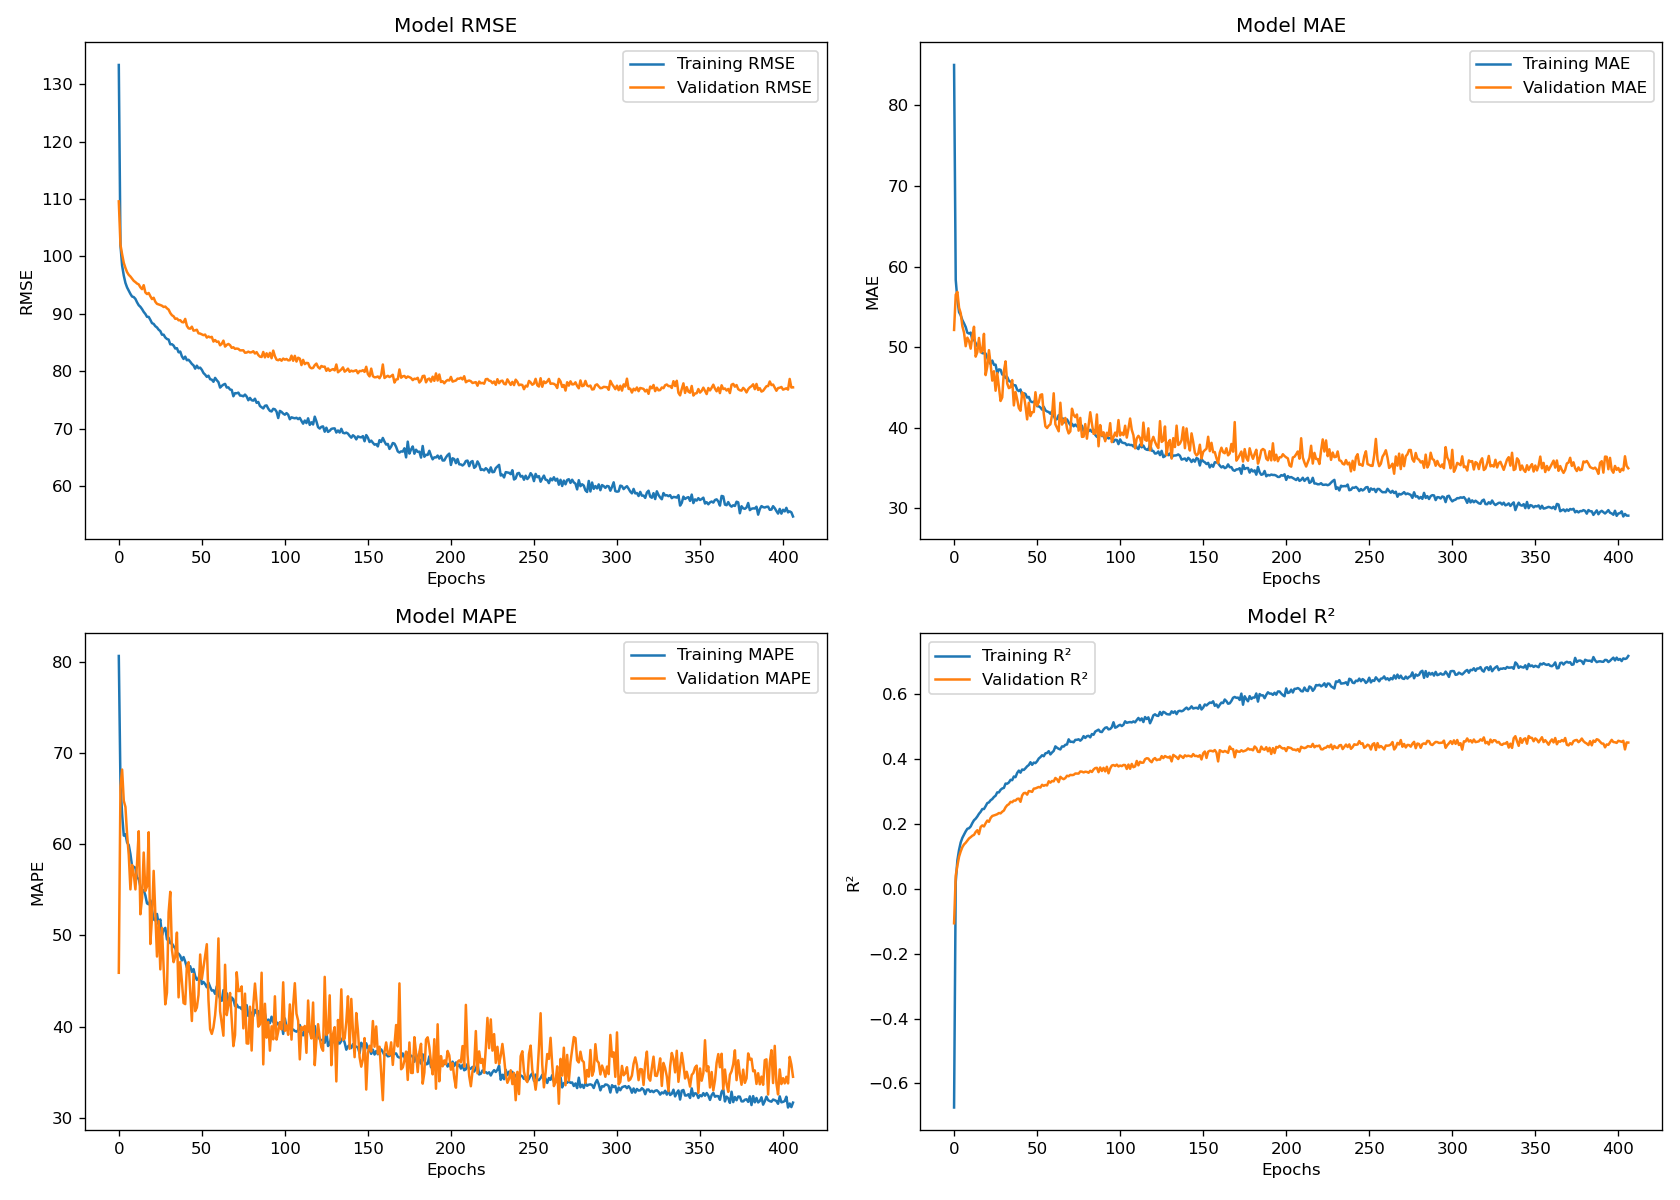

In [ ]:
# 56.12 Best ANN Result Evaluation & Plots
best_ann_row = ann_comparison_df.loc[[ann_comparison_df["R²"].idxmax()]]
display(best_ann_row)

best_cfg_id = 2
best_history = ann_histories[best_cfg_id]

# Training and Validation Plots
plt.figure(figsize=(14, 10))

# RMSE
plt.subplot(2, 2, 1)
plt.plot(best_history['rmse'], label='Training RMSE')
plt.plot(best_history['val_rmse'], label='Validation RMSE')
plt.title('Model RMSE')
plt.xlabel('Epochs')
plt.ylabel('RMSE')
plt.legend()

# MAE
plt.subplot(2, 2, 2)
plt.plot(best_history['mae'], label='Training MAE')
plt.plot(best_history['val_mae'], label='Validation MAE')
plt.title('Model MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()

# MAPE
plt.subplot(2, 2, 3)
plt.plot(best_history['mape'], label='Training MAPE')
plt.plot(best_history['val_mape'], label='Validation MAPE')
plt.title('Model MAPE')
plt.xlabel('Epochs')
plt.ylabel('MAPE')
plt.legend()

# R²
plt.subplot(2, 2, 4)
plt.plot(best_history['r2'], label='Training R²')
plt.plot(best_history['val_r2'], label='Validation R²')
plt.title('Model R²')
plt.xlabel('Epochs')
plt.ylabel('R²')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
# Check X (input features) and y (target)

print("X variables:")
print(X.columns.tolist())

print("\nY variable:")
print(y.name)

X variables:
['lights', 'RH_1', 'RH_2', 'T3', 'RH_3', 'T4', 'T5', 'RH_5', 'RH_6', 'RH_7', 'T8', 'RH_8', 'RH_9', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'Hour']

Y variable:
Appliances


In [ ]:
df.shape

(19735, 20)

In [ ]:
57. # Grid Search for Linear Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()

param_grid = {
    'fit_intercept': [True, False],
    'positive': [True, False]
}

grid_search = GridSearchCV(
    lr,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_lr = grid_search.best_estimator_

y_pred = best_lr.predict(X_test)

lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
lr_mae = mean_absolute_error(y_test, y_pred)
lr_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
lr_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", lr_rmse)
print("Test MAE:", lr_mae)
print("Test MAPE:", lr_mape)
print("Test R²:",lr_r2)

Best Parameters:
{'fit_intercept': True, 'positive': False}
Best CV R²:
0.1473757748798103
Test RMSE: 92.16557898717147
Test MAE: 53.234869063688166
Test MAPE: 63.4091137021531
Test R²: 0.15115253072087909


In [ ]:
58. # Grid Search for KNN Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

knn = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor())
])

param_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}

grid_search = GridSearchCV(
    knn,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_knn = grid_search.best_estimator_

y_pred = best_knn.predict(X_test)

knn_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
knn_mae = mean_absolute_error(y_test, y_pred)
knn_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
knn_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", knn_rmse)
print("Test MAE:", knn_mae)
print("Test MAPE:", knn_mape)
print("Test R²:", knn_r2)

Best Parameters:
{'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance'}
Best CV R²:
0.5182323283213421
Test RMSE: 64.98744934694217
Test MAE: 29.616076964777672
Test MAPE: 28.027917533371976
Test R²: 0.5779624135601961


In [ ]:
59. # Grid Search for Decision Tree Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

dt = DecisionTreeRegressor(random_state=42)

param_grid = {
    'max_depth': [10, 20, None],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    dt,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_dt = grid_search.best_estimator_

y_pred = best_dt.predict(X_test)

dt_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
dt_mae = mean_absolute_error(y_test, y_pred)
dt_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
dt_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", dt_rmse)
print("Test MAE:", dt_mae)
print("Test MAPE:", dt_mape)
print("Test R²:", dt_r2)

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 2}
Best CV R²:
0.2059533827453
Test RMSE: 89.4565696885468
Test MAE: 43.95452955377877
Test MAPE: 47.11444600304952
Test R²: 0.20031927507985114


In [ ]:
60. # Grid Search for Random Forest Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None]
}

grid_search = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_rf = grid_search.best_estimator_

y_pred = best_rf.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rf_mae = mean_absolute_error(y_test, y_pred)
rf_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
rf_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", rf_rmse)
print("Test MAE:", rf_mae)
print("Test MAPE:", rf_mape)
print("Test R²:", rf_r2)

Best Parameters:
{'max_depth': None, 'n_estimators': 200}
Best CV R²:
0.5050816975089111
Test RMSE: 66.17418319986078
Test MAE: 30.96746896376995
Test MAPE: 31.196798523748274
Test R²: 0.5624080483521371


In [ ]:
61. # Grid Search for AdaBoost Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ada = AdaBoostRegressor(random_state=42)

param_grid = {
    'n_estimators': [50, 100],
    'learning_rate': [0.05, 0.1, 0.5]
}

grid_search = GridSearchCV(
    ada,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_ada = grid_search.best_estimator_

y_pred = best_ada.predict(X_test)

ada_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
ada_mae = mean_absolute_error(y_test, y_pred)
ada_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
ada_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", ada_rmse)
print("Test MAE:", ada_mae)
print("Test MAPE:", ada_mape)
print("Test R²:", ada_r2)

Best Parameters:
{'learning_rate': 0.05, 'n_estimators': 50}
Best CV R²:
0.09284301638179152
Test RMSE: 97.05742154975403
Test MAE: 64.62687784352644
Test MAPE: 86.76316909724578
Test R²: 0.05865321007460933


In [ ]:
62. # Grid Search for Gradient Boosting Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

gb = GradientBoostingRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1, 0.2]
}

grid_search = GridSearchCV(
    gb,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_gb = grid_search.best_estimator_

y_pred = best_gb.predict(X_test)

gb_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
gb_mae = mean_absolute_error(y_test, y_pred)
gb_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
gb_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", gb_rmse)
print("Test MAE:", gb_mae)
print("Test MAPE:", gb_mape)
print("Test R²:", gb_r2)

Best Parameters:
{'learning_rate': 0.2, 'n_estimators': 200}
Best CV R²:
0.36514692942588695
Test RMSE: 79.19376061172392
Test MAE: 42.58780714694093
Test MAPE: 47.41515090589745
Test R²: 0.37327924160216563


In [ ]:
63.  # Grid Search for XGBoost Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

xgb = XGBRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 6]
}

grid_search = GridSearchCV(
    xgb,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_xgb = grid_search.best_estimator_

y_pred = best_xgb.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
xgb_mae = mean_absolute_error(y_test, y_pred)
xgb_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
xgb_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", xgb_rmse)
print("Test MAE:", xgb_mae)
print("Test MAPE:", xgb_mape)
print("Test R²:", xgb_r2)

Best Parameters:
{'learning_rate': 0.2, 'max_depth': 6}
Best CV R²:
0.49653013944625857
Test RMSE: 67.1833465285948
Test MAE: 33.51652908325195
Test MAPE: 35.10468304157257
Test R²: 0.5489595532417297


In [ ]:
64. # Grid Search for SVR Regression

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Wrapped SVR in Pipeline with StandardScaler to ensure proper feature scaling
svr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVR(kernel='rbf'))
])

param_grid = {
    'model__C': [10, 100],
    'model__epsilon': [0.1, 0.5]
}

grid_search = GridSearchCV(
    svr_pipeline,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R²:")
print(grid_search.best_score_)

best_svr = grid_search.best_estimator_

y_pred = best_svr.predict(X_test)

svr_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
svr_mae = mean_absolute_error(y_test, y_pred)
svr_mape = mean_absolute_percentage_error(y_test, y_pred) * 100
svr_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", svr_rmse)
print("Test MAE:", svr_mae)
print("Test MAPE:", svr_mape)
print("Test R²:", svr_r2)


Best Parameters:
{'model__C': 100, 'model__epsilon': 0.5}
Best CV R²:
0.22481941991926496
Test RMSE: 87.33091032512466
Test MAE: 35.994074548528125
Test MAPE: 28.174328479199573
Test R²: 0.2378716425655264


In [ ]:
65. # Compare all Grid Search results

grid_results = []

grid_results.append(["KNN", knn_rmse, knn_mae, knn_mape, knn_r2])
grid_results.append(["Decision Tree", dt_rmse, dt_mae, dt_mape, dt_r2])
grid_results.append(["Random Forest", rf_rmse, rf_mae, rf_mape, rf_r2])
grid_results.append(["AdaBoost", ada_rmse, ada_mae, ada_mape, ada_r2])
grid_results.append(["Gradient Boosting", gb_rmse, gb_mae, gb_mape, gb_r2])
grid_results.append(["XGBoost", xgb_rmse, xgb_mae, xgb_mape, xgb_r2])
grid_results.append(["SVR", svr_rmse, svr_mae, svr_mape, svr_r2])

grid_results = pd.DataFrame(
    grid_results,
    columns=["Model", "RMSE", "MAE", "MAPE", "R²"]
)

display(grid_results)


Model,RMSE,MAE,MAPE,R²
KNN,64.987449,29.616077,28.027918,0.577962
Decision Tree,89.456570,43.954530,47.114446,0.200319
Random Forest,66.174183,30.967469,31.196799,0.562408
AdaBoost,97.057422,64.626878,86.763169,0.058653
Gradient Boosting,79.193761,42.587807,47.415151,0.373279
XGBoost,67.183347,33.516529,35.104683,0.548960
SVR,87.330910,35.994075,28.174328,0.237872


In [ ]:
66.  # Model with Highest R²

highest_r2 = grid_results.loc[[grid_results["R²"].idxmax()]]

display(highest_r2)


Model,RMSE,MAE,MAPE,R²
KNN,64.987449,29.616077,28.027918,0.577962
